In [1]:
import sys
sys.path.append("../src")
import numpy as np, pandas as pd, json

%load_ext autoreload
%autoreload 2
import utils

OUT = "../data/processed/model_inputs"
with open(f"{OUT}/config.json") as f:
    cfg = json.load(f)

h = 1
load = lambda name: pd.read_csv(f"{OUT}/features_h{h}_{name}.csv",
                                parse_dates=["LocalDateTime"]).set_index("LocalDateTime")
train, val, test = load("train"), load("val"), load("test")

scale = utils.mase_scale(train["target"])
print("MASE scale (same hour last week, training set):", round(scale, 2))
print("Thresholds from config:", cfg["alert_threshold_p90_train"], cfg["alert_threshold_p95_train"])
print("Thresholds in utils:   ", utils.THRESHOLD_P90, utils.THRESHOLD_P95)

tt = test.index + pd.Timedelta(hours=h)
y = test["target"].to_numpy()

print("\nTest 1: a perfect forecast (everything should be 0 errors, recall 1)")
r = utils.evaluate(y, y, tt, scale)
print({k: round(v, 3) for k, v in r.items()})

print("\nTest 2: forecast always 5 too high (MAE 5, Bias +5, MASE = 5 / scale)")
r = utils.evaluate(y, y + 5, tt, scale)
print({k: round(v, 3) for k, v in r.items() if k in ["MAE", "RMSE", "Bias", "MASE", "Peak_MAE"]})

print("\nTest 3: forecast always 0 (no alerts ever: recall 0, precision undefined)")
r = utils.evaluate(y, np.zeros_like(y), tt, scale)
print({k: (round(v, 3) if v == v else None) for k, v in r.items()})

MASE scale (same hour last week, training set): 4.88
Thresholds from config: 65.0 73.0
Thresholds in utils:    65.0 73.0

Test 1: a perfect forecast (everything should be 0 errors, recall 1)
{'MAE': np.float64(0.0), 'RMSE': 0.0, 'WAPE': 0.0, 'MASE': 0.0, 'Bias': 0.0, 'Peak_MAE': 0.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0, 'F2': 1.0, 'FalseAlarmRate': 0.0, 'TP': 129, 'FP': 0, 'FN': 0, 'TN': 1262}

Test 2: forecast always 5 too high (MAE 5, Bias +5, MASE = 5 / scale)
{'MAE': np.float64(5.0), 'RMSE': 5.0, 'MASE': 1.024, 'Bias': 5.0, 'Peak_MAE': 5.0}

Test 3: forecast always 0 (no alerts ever: recall 0, precision undefined)
{'MAE': np.float64(29.951), 'RMSE': 39.374, 'WAPE': 1.0, 'MASE': 6.136, 'Bias': -29.951, 'Peak_MAE': 62.056, 'Precision': None, 'Recall': 0.0, 'F1': None, 'F2': None, 'FalseAlarmRate': 0.0, 'TP': 0, 'FP': 0, 'FN': 129, 'TN': 1262}


In [2]:
H = cfg["horizons"]
load = lambda h, name: pd.read_csv(f"{OUT}/features_h{h}_{name}.csv",
                                   parse_dates=["LocalDateTime"]).set_index("LocalDateTime")

data = {h: {n: load(h, n) for n in ["train", "val", "test"]} for h in H}
scale = utils.mase_scale(data[1]["train"]["target"])

def baseline_predictions(h, split):
    d, tr = data[h][split], data[h]["train"]
    profile = tr.groupby(["t_dow", "t_hour"])["target"].mean()
    prof_pred = pd.Series(list(zip(d["t_dow"], d["t_hour"]))).map(profile).to_numpy()
    return {
        "Current value": d["y_lag0"].to_numpy(),
        "Same hour yesterday": d["same_hour_yday"].to_numpy(),
        "Same hour last week": d["same_hour_lastweek"].to_numpy(),
        "Typical profile (train)": prof_pred,
    }

rows = []
for h in H:
    for split in ["val", "test"]:
        d = data[h][split]
        tt = d.index + pd.Timedelta(hours=h)
        for name, pred in baseline_predictions(h, split).items():
            assert not np.isnan(pred).any(), f"NaN in {name} (h={h}, {split})"
            r = utils.evaluate(d["target"].to_numpy(), pred, tt, scale)
            rows.append({"h": h, "split": split, "model": name, **r})

res = pd.DataFrame(rows)
show = ["MAE", "RMSE", "WAPE", "MASE", "Bias", "Peak_MAE", "Precision", "Recall", "F2"]
for split in ["val", "test"]:
    print(f"\n=== {split.upper()} ===")
    print(res[res["split"] == split].set_index(["h", "model"])[show].round(2).to_string())


=== VAL ===
                             MAE   RMSE  WAPE  MASE  Bias  Peak_MAE  Precision  Recall    F2
h model                                                                                     
1 Current value             6.05   8.91  0.20  1.24 -0.01      9.28       0.66    0.66  0.66
  Same hour yesterday       6.77  11.08  0.22  1.39 -0.03     11.63       0.54    0.53  0.53
  Same hour last week       3.92   6.93  0.13  0.80 -0.39      8.28       0.62    0.54  0.55
  Typical profile (train)   3.31   5.32  0.11  0.68  0.79      7.48       0.64    0.76  0.73
3 Current value            16.59  22.99  0.55  3.40 -0.06     14.52       0.18    0.18  0.18
  Same hour yesterday       6.78  11.09  0.22  1.39 -0.03     11.63       0.54    0.53  0.53
  Same hour last week       3.93   6.93  0.13  0.80 -0.39      8.28       0.62    0.54  0.55
  Typical profile (train)   3.31   5.32  0.11  0.68  0.80      7.48       0.64    0.76  0.73
6 Current value            28.91  35.68  0.96  5.92 -0.19

In [3]:
import time, warnings
import numpy.linalg as la
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import acf, pacf
warnings.filterwarnings("ignore")

# 1. Raw hourly series and the calendar information
raw = pd.read_csv("../data/processed/bangalore_traffic_weather.csv",
                  parse_dates=["LocalDateTime"]).set_index("LocalDateTime")
y_all = raw["TrafficIndexLive"].asfreq("h")
hol_days = pd.to_datetime(cfg["holidays"])
T_END = pd.Timestamp(cfg["split"]["train_target_end"])

y_tr = y_all[:T_END]
prof = y_tr.groupby([y_tr.index.day_of_week, y_tr.index.hour]).mean()   # training data only

def make_exog(idx):
    p = pd.Series(list(zip(idx.day_of_week, idx.hour)), index=idx).map(prof)
    return pd.DataFrame({"profile": p.to_numpy(),
                         "holiday": idx.normalize().isin(hol_days).astype(float)}, index=idx)

X_tr = make_exog(y_tr.index)
print("Training hours:", len(y_tr), "| missing exog:", int(X_tr.isna().sum().sum()),
      "| holiday hours:", int(X_tr["holiday"].sum()))

# 2. What is left over after the two regressors? (guides the ARMA order)
A = np.column_stack([np.ones(len(X_tr)), X_tr["profile"], X_tr["holiday"]])
beta = la.lstsq(A, y_tr.to_numpy(), rcond=None)[0]
u = pd.Series(y_tr.to_numpy() - A @ beta, index=y_tr.index)
print("\nRegression coefficients (const, profile, holiday):", beta.round(3))
print("Residual std:", round(u.std(), 2), "| MAE of the profile alone:", round(np.abs(y_tr - X_tr["profile"]).mean(), 2))
print("ACF  lags 1-6:", acf(u, nlags=6)[1:].round(2))
print("PACF lags 1-6:", pacf(u, nlags=6, method="ywm")[1:].round(2))

# 3. Compare candidate ARMA orders on the training data
rows, fits = [], {}
for order in [(1, 0, 0), (2, 0, 0), (1, 0, 1), (2, 0, 1), (3, 0, 1), (3, 0, 2)]:
    t0 = time.time()
    f = SARIMAX(y_tr, exog=X_tr, order=order, trend="c").fit(disp=False, maxiter=300)
    fits[order] = f
    rows.append({"order": order, "AIC": f.aic, "BIC": f.bic,
                 "converged": f.mle_retvals.get("converged"), "seconds": time.time() - t0})
print("\nCandidate orders:")
print(pd.DataFrame(rows).round(1).to_string(index=False))

Training hours: 12949 | missing exog: 0 | holiday hours: 792

Regression coefficients (const, profile, holiday): [ 0.521  1.001 -8.799]
Residual std: 6.93 | MAE of the profile alone: 4.24
ACF  lags 1-6: [0.89 0.75 0.62 0.5  0.42 0.35]
PACF lags 1-6: [ 0.89 -0.24 -0.02  0.02  0.05 -0.  ]

Candidate orders:
    order     AIC     BIC  converged  seconds
(1, 0, 0) 65835.2 65872.5       True      3.3
(2, 0, 0) 65032.1 65076.9       True      4.8
(1, 0, 1) 65116.2 65161.0       True      4.8
(2, 0, 1) 65029.0 65081.3       True      8.7
(3, 0, 1) 65029.3 65089.1       True     14.9
(3, 0, 2) 65031.1 65098.3       True     21.9


In [4]:
# Refit the chosen model; the constant goes in as an exog column
X_all = make_exog(y_all.index)
X_all.insert(0, "const", 1.0)
X_tr = X_all.loc[y_tr.index]

sx = SARIMAX(y_tr, exog=X_tr, order=(2, 0, 0), trend="n").fit(disp=False, maxiter=300)
print("Converged:", sx.mle_retvals.get("converged"))
print(sx.params.round(4).to_string())

b = sx.params[["const", "profile", "holiday"]].to_numpy()
p1, p2 = sx.params["ar.L1"], sx.params["ar.L2"]
u = pd.Series(y_all.to_numpy() - X_all.to_numpy() @ b, index=y_all.index)   # leftover errors
pos = {t: i for i, t in enumerate(y_all.index)}

def ar2_forecast(u_t, u_tm1, h):
    a, c = u_t, u_tm1
    for _ in range(h):
        a, c = p1 * a + p2 * c, a
    return a

# Check the hand-written forecasts against statsmodels at three origins (1 to 6 hours ahead)
sx_all = sx.apply(y_all, exog=X_all, refit=False)
for t in [pd.Timestamp("2026-07-15 17:00"), pd.Timestamp("2026-09-10 19:00"), pd.Timestamp("2026-10-20 19:00")]:
    i = pos[t]
    mine = np.array([X_all.iloc[i + k].to_numpy() @ b + ar2_forecast(u.iloc[i], u.iloc[i - 1], k)
                     for k in range(1, 7)])
    ref = sx_all.predict(start=i + 1, end=i + 6, dynamic=0).to_numpy()
    print(t, "max difference vs statsmodels:", float(np.abs(mine - ref).max()))

Converged: True
const      0.2040
profile    1.0002
holiday   -3.3980
ar.L1      1.1211
ar.L2     -0.2456
sigma2     8.8749
2026-07-15 17:00:00 max difference vs statsmodels: 1.4210854715202004e-14
2026-09-10 19:00:00 max difference vs statsmodels: 7.105427357601002e-15
2026-10-20 19:00:00 max difference vs statsmodels: 0.0


In [5]:
sar_rows = []
for h in H:
    for split in ["val", "test"]:
        d = data[h][split]
        ii = np.array([pos[t] for t in d.index])
        assert np.allclose(y_all.to_numpy()[ii + h], d["target"].to_numpy())   # alignment check
        uf = ar2_forecast(u.to_numpy()[ii], u.to_numpy()[ii - 1], h)
        pred = np.clip(X_all.to_numpy()[ii + h] @ b + uf, 0, None)
        tt = d.index + pd.Timedelta(hours=h)
        sar_rows.append({"h": h, "split": split, "model": "SARIMAX",
                         **utils.evaluate(d["target"].to_numpy(), pred, tt, scale)})

sar_df = pd.DataFrame(sar_rows)
all_res = pd.concat([res, sar_df], ignore_index=True)
cmp = all_res[all_res["model"].isin(["Typical profile (train)", "SARIMAX"])]
for split in ["val", "test"]:
    print(f"\n=== {split.upper()} ===")
    print(cmp[cmp["split"] == split].set_index(["h", "model"])[show].round(2).to_string())


=== VAL ===
                            MAE  RMSE  WAPE  MASE  Bias  Peak_MAE  Precision  Recall    F2
h model                                                                                   
1 Typical profile (train)  3.31  5.32  0.11  0.68  0.79      7.48       0.64    0.76  0.73
3 Typical profile (train)  3.31  5.32  0.11  0.68  0.80      7.48       0.64    0.76  0.73
6 Typical profile (train)  3.32  5.32  0.11  0.68  0.80      7.48       0.64    0.76  0.73
1 SARIMAX                  1.67  2.60  0.06  0.34  0.17      2.74       0.88    0.84  0.85
3 SARIMAX                  2.76  4.27  0.09  0.56  0.49      5.37       0.70    0.79  0.77
6 SARIMAX                  3.19  4.84  0.11  0.65  0.86      6.50       0.66    0.79  0.76

=== TEST ===
                            MAE  RMSE  WAPE  MASE  Bias  Peak_MAE  Precision  Recall    F2
h model                                                                                   
1 Typical profile (train)  4.20  8.02  0.14  0.86  1.01      8.

In [6]:
from prophet import Prophet
import logging
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
logging.getLogger("prophet").setLevel(logging.WARNING)

def day_flags(ds):
    dow = pd.DatetimeIndex(ds).day_of_week
    return pd.DataFrame({"is_sun": dow == 6, "is_sat": dow == 5, "is_wkday": dow < 5})

train_df = pd.DataFrame({"ds": y_tr.index, "y": y_tr.to_numpy()})
train_df = pd.concat([train_df, day_flags(train_df["ds"])], axis=1)

hol_df = pd.DataFrame({"holiday": "ka_holiday", "ds": hol_days})

m = Prophet(yearly_seasonality=False, weekly_seasonality=False, daily_seasonality=False, holidays=hol_df)
for name, cond in [("daily_sun", "is_sun"), ("daily_sat", "is_sat"), ("daily_wkday", "is_wkday")]:
    m.add_seasonality(name=name, period=1, fourier_order=12, condition_name=cond)
m.add_seasonality(name="weekly_level", period=7, fourier_order=3)

m.fit(train_df)

future = pd.DataFrame({"ds": pd.date_range(y_tr.index[0], y_all.index[-1], freq="h")})
future = pd.concat([future, day_flags(future["ds"])], axis=1)
fc = m.predict(future).set_index("ds")["yhat"].clip(lower=0)

print("Forecast hours:", len(fc), "| training MAE:", round(float(np.abs(y_tr - fc.loc[y_tr.index]).mean()), 2))

pro_rows = []
for h in H:
    for split in ["val", "test"]:
        d = data[h][split]
        tt = d.index + pd.Timedelta(hours=h)
        pred = fc.loc[tt].to_numpy()
        pro_rows.append({"h": h, "split": split, "model": "Prophet",
                         **utils.evaluate(d["target"].to_numpy(), pred, tt, scale)})

all_res = all_res[all_res["model"] != "Prophet"]
all_res = pd.concat([all_res, pd.DataFrame(pro_rows)], ignore_index=True)

keep = ["Typical profile (train)", "SARIMAX", "Prophet"]
for split in ["val", "test"]:
    print(f"\n=== {split.upper()} ===")
    t = all_res[(all_res["split"] == split) & (all_res["model"].isin(keep))]
    print(t.set_index(["h", "model"])[show].round(2).to_string())

Importing plotly failed. Interactive plots will not work.
10:02:47 - cmdstanpy - INFO - Chain [1] start processing
10:02:55 - cmdstanpy - INFO - Chain [1] done processing


Forecast hours: 15829 | training MAE: 4.2

=== VAL ===
                            MAE  RMSE  WAPE  MASE  Bias  Peak_MAE  Precision  Recall    F2
h model                                                                                   
1 Typical profile (train)  3.31  5.32  0.11  0.68  0.79      7.48       0.64    0.76  0.73
3 Typical profile (train)  3.31  5.32  0.11  0.68  0.80      7.48       0.64    0.76  0.73
6 Typical profile (train)  3.32  5.32  0.11  0.68  0.80      7.48       0.64    0.76  0.73
1 SARIMAX                  1.67  2.60  0.06  0.34  0.17      2.74       0.88    0.84  0.85
3 SARIMAX                  2.76  4.27  0.09  0.56  0.49      5.37       0.70    0.79  0.77
6 SARIMAX                  3.19  4.84  0.11  0.65  0.86      6.50       0.66    0.79  0.76
1 Prophet                  3.94  5.71  0.13  0.81  1.56      7.46       0.64    0.78  0.74
3 Prophet                  3.94  5.72  0.13  0.81  1.56      7.46       0.64    0.78  0.74
6 Prophet                  3.95  5.

In [8]:
import xgboost as xgb

g = cfg["feature_groups"]

def core_cols(h):
    gh = g[str(h)]
    return gh["calendar_target"] + gh["target_history"] + gh["history_target_hour"]

xgb_rows, xgb_models = [], {}
for h in H:
    cols = core_cols(h)
    tr, va, te = (data[h][k] for k in ["train", "val", "test"])

    m = xgb.XGBRegressor(
        n_estimators=6000, learning_rate=0.05, max_depth=4,
        subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
        eval_metric="mae", early_stopping_rounds=100,
        tree_method="hist", random_state=42, n_jobs=-1,
    )
    m.fit(tr[cols], tr["target"], eval_set=[(va[cols], va["target"])], verbose=False)
    xgb_models[h] = m
    print(f"h = {h}: {len(cols)} features, best iteration {m.best_iteration}")

    for split, d in [("val", va), ("test", te)]:
        pred = np.clip(m.predict(d[cols]), 0, None)
        tt = d.index + pd.Timedelta(hours=h)
        xgb_rows.append({"h": h, "split": split, "model": "XGBoost (core)",
                         **utils.evaluate(d["target"].to_numpy(), pred, tt, scale)})

all_res = all_res[all_res["model"] != "XGBoost (core)"]
all_res = pd.concat([all_res, pd.DataFrame(xgb_rows)], ignore_index=True)

keep = ["Typical profile (train)", "SARIMAX", "XGBoost (core)"]
for split in ["val", "test"]:
    print(f"\n=== {split.upper()} ===")
    t = all_res[(all_res["split"] == split) & (all_res["model"].isin(keep))]
    print(t.set_index(["h", "model"])[show].round(2).to_string())

for h in [1, 6]:
    imp = pd.Series(xgb_models[h].feature_importances_, index=core_cols(h)).sort_values(ascending=False)
    print(f"\nTop 8 features, h = {h}:")
    print(imp.head(8).round(3).to_string())

h = 1: 21 features, best iteration 1488
h = 3: 21 features, best iteration 1504
h = 6: 21 features, best iteration 964

=== VAL ===
                            MAE  RMSE  WAPE  MASE  Bias  Peak_MAE  Precision  Recall    F2
h model                                                                                   
1 Typical profile (train)  3.31  5.32  0.11  0.68  0.79      7.48       0.64    0.76  0.73
3 Typical profile (train)  3.31  5.32  0.11  0.68  0.80      7.48       0.64    0.76  0.73
6 Typical profile (train)  3.32  5.32  0.11  0.68  0.80      7.48       0.64    0.76  0.73
1 SARIMAX                  1.67  2.60  0.06  0.34  0.17      2.74       0.88    0.84  0.85
3 SARIMAX                  2.76  4.27  0.09  0.56  0.49      5.37       0.70    0.79  0.77
6 SARIMAX                  3.19  4.84  0.11  0.65  0.86      6.50       0.66    0.79  0.76
1 XGBoost (core)           1.36  2.17  0.05  0.28 -0.00      2.45       0.96    0.85  0.87
3 XGBoost (core)           2.15  3.61  0.07  0.44

In [9]:
t = all_res[(all_res["split"] == "test") & (all_res["model"].isin(["SARIMAX", "XGBoost (core)"]))]
print(t.set_index(["h", "model"])[show].round(2).to_string())

for h in [1, 6]:
    imp = pd.Series(xgb_models[h].feature_importances_, index=core_cols(h)).sort_values(ascending=False)
    print(f"\nTop 8 features, h = {h}:")
    print(imp.head(8).round(3).to_string())

                   MAE  RMSE  WAPE  MASE  Bias  Peak_MAE  Precision  Recall    F2
h model                                                                          
1 SARIMAX         2.04  3.24  0.07  0.42  0.18      3.45       0.94    0.91  0.91
3 SARIMAX         3.52  5.92  0.12  0.72  0.56      5.90       0.92    0.86  0.87
6 SARIMAX         4.03  7.05  0.13  0.83  0.93      6.91       0.86    0.87  0.87
1 XGBoost (core)  1.70  2.76  0.06  0.35 -0.00      3.13       0.94    0.91  0.91
3 XGBoost (core)  2.96  5.00  0.10  0.61  0.14      5.49       0.90    0.79  0.81
6 XGBoost (core)  3.41  5.86  0.11  0.70  0.05      6.48       0.90    0.85  0.86

Top 8 features, h = 1:
same_hour_lastweek    0.494
y_lag0                0.136
same_hour_yday        0.103
t_hour                0.077
t_hour_cos            0.060
t_hour_sin            0.049
t_is_sunday           0.021
t_is_holiday          0.018

Top 8 features, h = 6:
same_hour_lastweek    0.492
same_hour_yday        0.183
t_hour          

In [10]:
import time

def variant_cols(h, extra):
    gh = cfg["feature_groups"][str(h)]
    cols = gh["calendar_target"] + gh["target_history"] + gh["history_target_hour"]
    for name in extra:
        cols = cols + gh[name]
    return cols

variants = {
    "core": ([], 42),
    "core (seed 43)": ([], 43),
    "+jam": (["jam"], 42),
    "+weather": (["weather_basic"], 42),
    "+weather+tempchange": (["weather_basic", "weather_tempchange"], 42),
    "+tomtom benchmark": (["tomtom_benchmark"], 42),
    "+monsoon flag": (["monsoon_flag"], 42),
    "+jam+weather": (["jam", "weather_basic"], 42),
    "UPPER BOUND: target-hour weather": (["weather_target_hour_UPPER_BOUND"], 42),
}

abl_rows = []
t0 = time.time()
for vname, (extra, seed) in variants.items():
    for h in H:
        cols = variant_cols(h, extra)
        tr, va, te = (data[h][k] for k in ["train", "val", "test"])
        m = xgb.XGBRegressor(
            n_estimators=6000, learning_rate=0.05, max_depth=4,
            subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
            eval_metric="mae", early_stopping_rounds=100,
            tree_method="hist", random_state=seed, n_jobs=-1,
        )
        m.fit(tr[cols], tr["target"], eval_set=[(va[cols], va["target"])], verbose=False)
        for split, d in [("val", va), ("test", te)]:
            pred = np.clip(m.predict(d[cols]), 0, None)
            tt = d.index + pd.Timedelta(hours=h)
            abl_rows.append({"variant": vname, "h": h, "split": split, "features": len(cols),
                             "best_iter": m.best_iteration,
                             **utils.evaluate(d["target"].to_numpy(), pred, tt, scale)})
    print(f"{vname:<36} done  ({(time.time() - t0) / 60:.1f} min elapsed)")

abl = pd.DataFrame(abl_rows)
os.makedirs("../results", exist_ok=True)
abl.to_csv("../results/ablation_xgb.csv", index=False)
all_res.to_csv("../results/model_results.csv", index=False)

order = list(variants)
for split in ["val", "test"]:
    for metric in ["MAE", "Peak_MAE", "Recall", "F2"]:
        print(f"\n{split.upper()} - {metric}")
        print(abl[abl["split"] == split].pivot(index="variant", columns="h", values=metric)
              .loc[order].round(2).to_string())

print("\nBest iterations (should stay well below 6000):")
print(abl[abl["split"] == "test"].pivot(index="variant", columns="h", values="best_iter").loc[order].to_string())

core                                 done  (0.4 min elapsed)
core (seed 43)                       done  (0.8 min elapsed)
+jam                                 done  (1.2 min elapsed)
+weather                             done  (1.5 min elapsed)
+weather+tempchange                  done  (2.0 min elapsed)
+tomtom benchmark                    done  (2.5 min elapsed)
+monsoon flag                        done  (2.9 min elapsed)
+jam+weather                         done  (3.5 min elapsed)
UPPER BOUND: target-hour weather     done  (3.9 min elapsed)


NameError: name 'os' is not defined

In [11]:
import os, time
import numpy as np, pandas as pd
import xgboost as xgb

def variant_cols(h, extra):
    gh = cfg["feature_groups"][str(h)]
    cols = gh["calendar_target"] + gh["target_history"] + gh["history_target_hour"]
    for name in extra:
        cols = cols + gh[name]
    return cols

variants = {
    "core": ([], 42),
    "core (seed 43)": ([], 43),
    "+jam": (["jam"], 42),
    "+weather": (["weather_basic"], 42),
    "+weather+tempchange": (["weather_basic", "weather_tempchange"], 42),
    "+tomtom benchmark": (["tomtom_benchmark"], 42),
    "+monsoon flag": (["monsoon_flag"], 42),
    "+jam+weather": (["jam", "weather_basic"], 42),
    "UPPER BOUND: target-hour weather": (["weather_target_hour_UPPER_BOUND"], 42),
}

abl_rows = []
t0 = time.time()
for vname, (extra, seed) in variants.items():
    for h in H:
        cols = variant_cols(h, extra)
        tr, va, te = (data[h][k] for k in ["train", "val", "test"])
        m = xgb.XGBRegressor(
            n_estimators=6000, learning_rate=0.05, max_depth=4,
            subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
            eval_metric="mae", early_stopping_rounds=100,
            tree_method="hist", random_state=seed, n_jobs=-1,
        )
        m.fit(tr[cols], tr["target"], eval_set=[(va[cols], va["target"])], verbose=False)
        for split, d in [("val", va), ("test", te)]:
            pred = np.clip(m.predict(d[cols]), 0, None)
            tt = d.index + pd.Timedelta(hours=h)
            abl_rows.append({"variant": vname, "h": h, "split": split, "features": len(cols),
                             "best_iter": m.best_iteration,
                             **utils.evaluate(d["target"].to_numpy(), pred, tt, scale)})
    print(f"{vname:<36} done  ({(time.time() - t0) / 60:.1f} min elapsed)")

abl = pd.DataFrame(abl_rows)

# Save results
os.makedirs("../results", exist_ok=True)
abl.to_csv("../results/ablation_xgb.csv", index=False)
all_res.to_csv("../results/model_results.csv", index=False)
print("\nSaved to ../results/  (", len(abl), "rows in the ablation )")

# Print results
order = list(variants)
for split in ["val", "test"]:
    for metric in ["MAE", "Peak_MAE", "Recall", "F2"]:
        print(f"\n{split.upper()} - {metric}")
        print(abl[abl["split"] == split].pivot(index="variant", columns="h", values=metric)
              .loc[order].round(2).to_string())

print("\nBest iterations (should stay well below 6000):")
print(abl[abl["split"] == "test"].pivot(index="variant", columns="h", values="best_iter")
      .loc[order].to_string())

core                                 done  (0.5 min elapsed)
core (seed 43)                       done  (1.0 min elapsed)
+jam                                 done  (1.4 min elapsed)
+weather                             done  (1.7 min elapsed)
+weather+tempchange                  done  (2.3 min elapsed)
+tomtom benchmark                    done  (2.8 min elapsed)
+monsoon flag                        done  (3.4 min elapsed)
+jam+weather                         done  (4.3 min elapsed)
UPPER BOUND: target-hour weather     done  (4.9 min elapsed)

Saved to ../results/  ( 54 rows in the ablation )

VAL - MAE
h                                    1     3     6
variant                                           
core                              1.36  2.15  2.45
core (seed 43)                    1.37  2.14  2.42
+jam                              1.41  2.27  2.50
+weather                          1.36  2.17  2.32
+weather+tempchange               1.36  2.09  2.31
+tomtom benchmark               

In [12]:
import pandas as pd
abl = pd.read_csv("../results/ablation_xgb.csv")
order = ["core", "core (seed 43)", "+jam", "+weather", "+weather+tempchange",
         "+tomtom benchmark", "+monsoon flag", "+jam+weather", "UPPER BOUND: target-hour weather"]

def delta(metric):
    t = abl.pivot_table(index="variant", columns=["split", "h"], values=metric).loc[order]
    return (t - t.loc["core"]).round(2)

for metric in ["MAE", "Peak_MAE", "Recall", "F2"]:
    print(f"\n{metric}: difference from core  (columns = split, horizon)")
    print(delta(metric).to_string())


MAE: difference from core  (columns = split, horizon)
split                             test               val            
h                                    1     3     6     1     3     6
variant                                                             
core                              0.00  0.00  0.00  0.00  0.00  0.00
core (seed 43)                   -0.01 -0.03 -0.04  0.02 -0.02 -0.03
+jam                             -0.01 -0.03 -0.09  0.05  0.12  0.05
+weather                          0.06  0.14  0.13  0.00  0.01 -0.13
+weather+tempchange               0.05  0.14  0.21  0.01 -0.06 -0.14
+tomtom benchmark                -0.09 -0.16 -0.15 -0.05  0.10  0.06
+monsoon flag                    -0.01  0.02  0.06  0.00  0.03  0.02
+jam+weather                      0.04  0.04  0.11  0.08  0.04 -0.14
UPPER BOUND: target-hour weather -0.07 -0.02 -0.05 -0.00 -0.06 -0.09

Peak_MAE: difference from core  (columns = split, horizon)
split                             test               val 

In [13]:
sub = abl[(abl["split"] == "test") & abl["variant"].isin(["core", "core (seed 43)", "+weather", "+weather+tempchange", "+tomtom benchmark", "UPPER BOUND: target-hour weather"])]
for metric in ["Recall", "Precision", "F2"]:
    print(f"\n{metric} (test)")
    print(sub.pivot(index="variant", columns="h", values=metric).round(2).to_string())


Recall (test)
h                                    1     3     6
variant                                           
+tomtom benchmark                 0.89  0.84  0.84
+weather                          0.92  0.85  0.84
+weather+tempchange               0.90  0.83  0.82
UPPER BOUND: target-hour weather  0.91  0.82  0.84
core                              0.91  0.79  0.85
core (seed 43)                    0.91  0.79  0.84

Precision (test)
h                                    1     3     6
variant                                           
+tomtom benchmark                 0.93  0.92  0.89
+weather                          0.94  0.91  0.89
+weather+tempchange               0.94  0.91  0.88
UPPER BOUND: target-hour weather  0.93  0.91  0.88
core                              0.94  0.90  0.90
core (seed 43)                    0.94  0.89  0.89

F2 (test)
h                                    1     3     6
variant                                           
+tomtom benchmark                 0.90

In [14]:
import os, time, random
import numpy as np, pandas as pd
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
from tensorflow import keras

OUT = "../data/processed/model_inputs"
seq_cols = cfg["sequence_columns"]
n_core = 7                                   # first 7 sequence columns = core group
print("Sequence columns used in this run:", seq_cols[:n_core])

def set_seed(s):
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)

def build_model(n_steps, n_seq, n_static):
    seq_in = keras.Input(shape=(n_steps, n_seq))
    sta_in = keras.Input(shape=(n_static,))
    a = keras.layers.LSTM(64)(seq_in)
    b = keras.layers.Dense(16, activation="relu")(sta_in)
    x = keras.layers.Concatenate()([a, b])
    x = keras.layers.Dense(32, activation="relu")(x)
    x = keras.layers.Dropout(0.1)(x)
    out = keras.layers.Dense(1)(x)
    m = keras.Model([seq_in, sta_in], out)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mae")
    return m

lstm_rows, histories = [], {}
t0 = time.time()
for h in H:
    z = np.load(f"{OUT}/lstm_windows_h{h}.npz", allow_pickle=True)
    Xs = {k: z[f"{k}_seq"][:, :, :n_core] for k in ["train", "val", "test"]}
    St = {k: z[f"{k}_static"] for k in ["train", "val", "test"]}
    Y  = {k: z[f"{k}_y"] for k in ["train", "val", "test"]}
    IDX = {k: pd.DatetimeIndex(z[f"{k}_index"]) for k in ["train", "val", "test"]}

    set_seed(42)
    model = build_model(Xs["train"].shape[1], n_core, St["train"].shape[1])
    cb = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
    hist = model.fit([Xs["train"], St["train"]], Y["train"],
                     validation_data=([Xs["val"], St["val"]], Y["val"]),
                     epochs=60, batch_size=128, callbacks=[cb], verbose=0)
    histories[h] = hist.history
    best_ep = int(np.argmin(hist.history["val_loss"])) + 1
    print(f"h = {h}: {len(hist.history['loss'])} epochs run, best epoch {best_ep}, "
          f"val MAE {min(hist.history['val_loss']):.2f}  ({(time.time() - t0) / 60:.1f} min elapsed)")

    for split in ["val", "test"]:
        pred = np.clip(model.predict([Xs[split], St[split]], verbose=0).ravel(), 0, None)
        tt = IDX[split] + pd.Timedelta(hours=h)
        lstm_rows.append({"h": h, "split": split, "model": "LSTM (core, 24h)",
                          **utils.evaluate(Y[split], pred, tt, scale)})

all_res = all_res[all_res["model"] != "LSTM (core, 24h)"]
all_res = pd.concat([all_res, pd.DataFrame(lstm_rows)], ignore_index=True)
all_res.to_csv("../results/model_results.csv", index=False)

keep = ["SARIMAX", "XGBoost (core)", "LSTM (core, 24h)"]
for split in ["val", "test"]:
    print(f"\n=== {split.upper()} ===")
    t = all_res[(all_res["split"] == split) & (all_res["model"].isin(keep))]
    print(t.set_index(["h", "model"])[show].round(2).to_string())

Sequence columns used in this run: ['y_lag0', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_sunday', 'is_holiday']
h = 1: 43 epochs run, best epoch 35, val MAE 1.54  (1.9 min elapsed)
h = 3: 32 epochs run, best epoch 24, val MAE 2.26  (3.4 min elapsed)
h = 6: 38 epochs run, best epoch 30, val MAE 2.39  (5.9 min elapsed)

=== VAL ===
                     MAE  RMSE  WAPE  MASE  Bias  Peak_MAE  Precision  Recall    F2
h model                                                                            
1 SARIMAX           1.67  2.60  0.06  0.34  0.17      2.74       0.88    0.84  0.85
3 SARIMAX           2.76  4.27  0.09  0.56  0.49      5.37       0.70    0.79  0.77
6 SARIMAX           3.19  4.84  0.11  0.65  0.86      6.50       0.66    0.79  0.76
1 XGBoost (core)    1.36  2.17  0.05  0.28 -0.00      2.45       0.96    0.85  0.87
3 XGBoost (core)    2.15  3.61  0.07  0.44 -0.04      4.09       0.88    0.75  0.77
6 XGBoost (core)    2.45  4.19  0.08  0.50 -0.18      4.41       0.84    

In [15]:
import os, time, random
import numpy as np, pandas as pd
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
from tensorflow import keras

OUT = "../data/processed/model_inputs"
seq_cols = cfg["sequence_columns"]
assert seq_cols[7] == "jcount_lag0" and seq_cols[12] == "temperature_2m"   # column layout check
core_i, jam_i, wx_i = list(range(0, 7)), list(range(7, 12)), list(range(12, len(seq_cols)))

def set_seed(s):
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)

def build_model(n_steps, n_seq, n_static):
    seq_in = keras.Input(shape=(n_steps, n_seq))
    sta_in = keras.Input(shape=(n_static,))
    a = keras.layers.LSTM(64)(seq_in)
    b = keras.layers.Dense(16, activation="relu")(sta_in)
    x = keras.layers.Concatenate()([a, b])
    x = keras.layers.Dense(32, activation="relu")(x)
    x = keras.layers.Dropout(0.1)(x)
    out = keras.layers.Dense(1)(x)
    m = keras.Model([seq_in, sta_in], out)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mae")
    return m

lstm_variants = {
    "LSTM core (seed 43)":    (core_i, 43),
    "LSTM +weather":          (core_i + wx_i, 42),
    "LSTM +jam":              (core_i + jam_i, 42),
    "LSTM +jam+weather":      (core_i + jam_i + wx_i, 42),
}

windows_cache = {}
for h in H:
    z = np.load(f"{OUT}/lstm_windows_h{h}.npz", allow_pickle=True)
    windows_cache[h] = {
        "seq": {k: z[f"{k}_seq"] for k in ["train", "val", "test"]},
        "sta": {k: z[f"{k}_static"] for k in ["train", "val", "test"]},
        "y":   {k: z[f"{k}_y"] for k in ["train", "val", "test"]},
        "idx": {k: pd.DatetimeIndex(z[f"{k}_index"]) for k in ["train", "val", "test"]},
    }

lstm_abl_rows = []
t0 = time.time()
for vname, (cols_i, seed) in lstm_variants.items():
    for h in H:
        w = windows_cache[h]
        Xs = {k: w["seq"][k][:, :, cols_i] for k in w["seq"]}
        set_seed(seed)
        model = build_model(Xs["train"].shape[1], len(cols_i), w["sta"]["train"].shape[1])
        cb = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
        hist = model.fit([Xs["train"], w["sta"]["train"]], w["y"]["train"],
                         validation_data=([Xs["val"], w["sta"]["val"]], w["y"]["val"]),
                         epochs=60, batch_size=128, callbacks=[cb], verbose=0)
        best_ep = int(np.argmin(hist.history["val_loss"])) + 1
        for split in ["val", "test"]:
            pred = np.clip(model.predict([Xs[split], w["sta"][split]], verbose=0).ravel(), 0, None)
            tt = w["idx"][split] + pd.Timedelta(hours=h)
            lstm_abl_rows.append({"variant": vname, "h": h, "split": split, "features": len(cols_i),
                                  "best_epoch": best_ep,
                                  **utils.evaluate(w["y"][split], pred, tt, scale)})
        print(f"{vname:<22} h={h}  best epoch {best_ep:>2}  val MAE {min(hist.history['val_loss']):.2f}"
              f"   ({(time.time() - t0) / 60:.1f} min elapsed)")
    pd.DataFrame(lstm_abl_rows).to_csv("../results/ablation_lstm.csv", index=False)   # saved after each variant

lab = pd.DataFrame(lstm_abl_rows)

# Add the core LSTM from step 4.8 as the reference row
ref = all_res[all_res["model"] == "LSTM (core, 24h)"].copy()
ref["variant"] = "LSTM core (seed 42)"
ref["best_epoch"] = np.nan
ref["features"] = len(core_i)
lab = pd.concat([lab, ref.drop(columns=["model"])], ignore_index=True)
lab.to_csv("../results/ablation_lstm.csv", index=False)

order = ["LSTM core (seed 42)", "LSTM core (seed 43)", "LSTM +jam", "LSTM +weather", "LSTM +jam+weather"]
print("\n=== Difference from LSTM core (seed 42)   (columns = split, horizon) ===")
for metric in ["MAE", "Peak_MAE", "Bias", "Recall", "F2"]:
    t = lab.pivot_table(index="variant", columns=["split", "h"], values=metric).loc[order]
    print(f"\n{metric}")
    print((t - t.loc["LSTM core (seed 42)"]).round(2).to_string())

print("\nTest MAE and F2 in full:")
for metric in ["MAE", "F2"]:
    t = lab[lab["split"] == "test"].pivot(index="variant", columns="h", values=metric).loc[order]
    print(f"\n{metric} (test)")
    print(t.round(2).to_string())

LSTM core (seed 43)    h=1  best epoch 30  val MAE 1.57   (2.4 min elapsed)
LSTM core (seed 43)    h=3  best epoch 28  val MAE 2.25   (4.2 min elapsed)
LSTM core (seed 43)    h=6  best epoch 38  val MAE 2.47   (6.7 min elapsed)
LSTM +weather          h=1  best epoch 30  val MAE 1.60   (8.9 min elapsed)
LSTM +weather          h=3  best epoch 24  val MAE 2.40   (10.0 min elapsed)
LSTM +weather          h=6  best epoch 20  val MAE 2.65   (11.1 min elapsed)
LSTM +jam              h=1  best epoch 41  val MAE 1.38   (13.0 min elapsed)
LSTM +jam              h=3  best epoch 39  val MAE 2.20   (15.0 min elapsed)
LSTM +jam              h=6  best epoch 25  val MAE 2.43   (17.3 min elapsed)
LSTM +jam+weather      h=1  best epoch 18  val MAE 1.59   (18.5 min elapsed)
LSTM +jam+weather      h=3  best epoch 13  val MAE 2.27   (19.8 min elapsed)
LSTM +jam+weather      h=6  best epoch 18  val MAE 2.49   (21.2 min elapsed)

=== Difference from LSTM core (seed 42)   (columns = split, horizon) ===

MAE
s

In [16]:
import os, random, time
import numpy as np, pandas as pd
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
from tensorflow import keras

needed = ["data", "H", "cfg", "utils", "scale", "xgb_models", "core_cols", "fc", "X_all", "b", "u",
          "pos", "ar2_forecast", "y_all", "baseline_predictions", "build_model", "set_seed"]
missing = [n for n in needed if n not in globals()]
assert not missing, f"Run the earlier cells first. Missing: {missing}"

parts = []
def add(model, h, split, origins, actual, pred):
    parts.append(pd.DataFrame({
        "origin": origins, "target_time": origins + pd.Timedelta(hours=h),
        "h": h, "split": split, "model": model,
        "actual": np.asarray(actual, float), "pred": np.asarray(pred, float)}))

# 1. Baselines, Prophet, SARIMAX, XGBoost
for h in H:
    for split in ["val", "test"]:
        d = data[h][split]
        y = d["target"].to_numpy()

        for name, p in baseline_predictions(h, split).items():
            add(name, h, split, d.index, y, p)

        add("Prophet", h, split, d.index, y, fc.loc[d.index + pd.Timedelta(hours=h)].to_numpy())

        ii = np.array([pos[t] for t in d.index])
        assert np.allclose(y_all.to_numpy()[ii + h], y)
        uf = ar2_forecast(u.to_numpy()[ii], u.to_numpy()[ii - 1], h)
        add("SARIMAX", h, split, d.index, y, np.clip(X_all.to_numpy()[ii + h] @ b + uf, 0, None))

        add("XGBoost (core)", h, split, d.index, y,
            np.clip(xgb_models[h].predict(d[core_cols(h)]), 0, None))
print("Non-LSTM forecasts collected.")

# 2. LSTM (core features), average of 3 seeds
OUT = "../data/processed/model_inputs"
SEEDS, n_core = [42, 43, 44], 7
t0 = time.time()
for h in H:
    z = np.load(f"{OUT}/lstm_windows_h{h}.npz", allow_pickle=True)
    Xs = {k: z[f"{k}_seq"][:, :, :n_core] for k in ["train", "val", "test"]}
    St = {k: z[f"{k}_static"] for k in ["train", "val", "test"]}
    Y = {k: z[f"{k}_y"] for k in ["train", "val", "test"]}
    for k in ["val", "test"]:
        idx_saved = pd.DatetimeIndex(z[f"{k}_index"]).values.astype("datetime64[s]")
        assert np.array_equal(idx_saved, data[h][k].index.values.astype("datetime64[s]"))
        assert np.allclose(Y[k], data[h][k]["target"].to_numpy())

    preds = {"val": [], "test": []}
    for seed in SEEDS:
        set_seed(seed)
        model = build_model(Xs["train"].shape[1], n_core, St["train"].shape[1])
        cb = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
        hist = model.fit([Xs["train"], St["train"]], Y["train"],
                         validation_data=([Xs["val"], St["val"]], Y["val"]),
                         epochs=60, batch_size=128, callbacks=[cb], verbose=0)
        for k in preds:
            preds[k].append(model.predict([Xs[k], St[k]], verbose=0).ravel())
        print(f"h={h} seed={seed}: best epoch {int(np.argmin(hist.history['val_loss'])) + 1}"
              f"  ({(time.time() - t0) / 60:.1f} min elapsed)")
    for k in ["val", "test"]:
        add("LSTM (core, 3-seed avg)", h, k, data[h][k].index, Y[k],
            np.clip(np.mean(preds[k], axis=0), 0, None))

# 3. Save the forecasts and recompute every metric from them
os.makedirs("../results", exist_ok=True)
pred_df = pd.concat(parts, ignore_index=True)
assert pred_df["pred"].notna().all()
pred_df.to_csv("../results/predictions_val_test.csv", index=False)

rows = []
for (m, h, s), g in pred_df.groupby(["model", "h", "split"]):
    rows.append({"model": m, "h": h, "split": s,
                 **utils.evaluate(g["actual"].to_numpy(), g["pred"].to_numpy(),
                                  pd.DatetimeIndex(g["target_time"]), scale)})
final = pd.DataFrame(rows)
final.to_csv("../results/final_metrics.csv", index=False)
print("\nSaved:", len(pred_df), "forecast rows,", len(final), "metric rows")

order = ["Current value", "Same hour yesterday", "Same hour last week", "Typical profile (train)",
         "Prophet", "SARIMAX", "XGBoost (core)", "LSTM (core, 3-seed avg)"]
for split, metric in [("val", "MAE"), ("test", "MAE"), ("test", "F2")]:
    print(f"\n{metric} ({split})")
    print(final[final["split"] == split].pivot(index="model", columns="h", values=metric)
          .loc[order].round(2).to_string())

Non-LSTM forecasts collected.
h=1 seed=42: best epoch 35  (2.6 min elapsed)
h=1 seed=43: best epoch 30  (4.1 min elapsed)
h=1 seed=44: best epoch 49  (6.0 min elapsed)
h=3 seed=42: best epoch 24  (7.2 min elapsed)
h=3 seed=43: best epoch 28  (8.4 min elapsed)
h=3 seed=44: best epoch 24  (9.4 min elapsed)
h=6 seed=42: best epoch 30  (10.6 min elapsed)
h=6 seed=43: best epoch 38  (12.2 min elapsed)
h=6 seed=44: best epoch 47  (13.9 min elapsed)

Saved: 68960 forecast rows, 48 metric rows

MAE (val)
h                           1      3      6
model                                      
Current value            6.05  16.59  28.91
Same hour yesterday      6.77   6.78   6.79
Same hour last week      3.92   3.93   3.93
Typical profile (train)  3.31   3.31   3.32
Prophet                  3.94   3.94   3.95
SARIMAX                  1.67   2.76   3.19
XGBoost (core)           1.36   2.15   2.45
LSTM (core, 3-seed avg)  1.46   2.16   2.35

MAE (test)
h                           1      3      6
mo

In [17]:
import pandas as pd

final = pd.read_csv("../results/final_metrics.csv")
order = ["Current value", "Same hour yesterday", "Same hour last week", "Typical profile (train)",
         "Prophet", "SARIMAX", "XGBoost (core)", "LSTM (core, 3-seed avg)"]

for metric in ["MAE", "RMSE", "Peak_MAE", "Bias"]:
    print(f"\n{metric} (test)")
    print(final[final["split"] == "test"].pivot(index="model", columns="h", values=metric)
          .loc[order].round(2).to_string())


MAE (test)
h                           1      3      6
model                                      
Current value            6.40  17.55  28.90
Same hour yesterday      6.83   6.84   6.86
Same hour last week      6.62   6.63   6.64
Typical profile (train)  4.20   4.20   4.21
Prophet                  5.45   5.45   5.45
SARIMAX                  2.04   3.52   4.03
XGBoost (core)           1.70   2.96   3.41
LSTM (core, 3-seed avg)  1.79   2.88   3.15

RMSE (test)
h                            1      3      6
model                                       
Current value             9.37  23.87  36.21
Same hour yesterday      11.17  11.18  11.19
Same hour last week      11.97  11.98  11.99
Typical profile (train)   8.02   8.02   8.04
Prophet                   8.02   8.02   8.03
SARIMAX                   3.24   5.92   7.05
XGBoost (core)            2.76   5.00   5.86
LSTM (core, 3-seed avg)   3.05   5.26   5.79

Peak_MAE (test)
h                            1      3      6
model                  

In [18]:
import numpy as np, pandas as pd

P = pd.read_csv("../results/predictions_val_test.csv", parse_dates=["origin", "target_time"])
models = ["Typical profile (train)", "Prophet", "SARIMAX", "XGBoost (core)", "LSTM (core, 3-seed avg)"]
THR = {"warning (65)": 65.0, "severe (73)": 73.0}

def episodes(actual_alert):
    """Start and end positions of runs of consecutive True values."""
    a = np.asarray(actual_alert, bool)
    starts = np.where(a & ~np.r_[False, a[:-1]])[0]
    ends = np.where(a & ~np.r_[a[1:], False])[0]
    return list(zip(starts, ends))

def alert_report(g, thr, cutoff):
    g = g.sort_values("target_time")
    actual = g["actual"].to_numpy() >= thr
    alert = g["pred"].to_numpy() >= cutoff
    eps = episodes(actual)
    detected, leads = 0, []
    for s, e in eps:
        window = alert[max(0, s - 6): e + 1]                       # alerts up to 6 hours before, or during the episode
        if window.any():
            detected += 1
            first = np.argmax(window) + max(0, s - 6)
            leads.append(s - first)                                  # hours before the start (negative = after it began)
    m = utils.alert_metrics(g["actual"].to_numpy(), g["pred"].to_numpy() - cutoff + thr, thr)
    weeks = (g["target_time"].max() - g["target_time"].min()).days / 7
    in_ep = np.zeros(len(actual), bool)
    for s, e in eps:
        in_ep[s: e + 1] = True
    return {"episodes": len(eps), "detected": detected,
            "episode_recall": detected / len(eps) if eps else np.nan,
            "median_lead_h": float(np.median(leads)) if leads else np.nan,
            "false_alarm_hrs_per_week": float((alert & ~in_ep).sum() / weeks),
            "Precision": m["Precision"], "Recall": m["Recall"], "F2": m["F2"]}

def best_cutoff(g_val, thr):
    best, best_f2 = thr, -1
    for c in np.arange(thr - 15, thr + 0.5, 1.0):
        f2 = utils.alert_metrics(g_val["actual"].to_numpy(), g_val["pred"].to_numpy() - c + thr, thr)["F2"]
        if f2 == f2 and f2 > best_f2:
            best, best_f2 = c, f2
    return best

rows = []
for m in models:
    for h in [1, 3, 6]:
        gv = P[(P.model == m) & (P.h == h) & (P.split == "val")]
        gt = P[(P.model == m) & (P.h == h) & (P.split == "test")]
        for tname, thr in THR.items():
            c = best_cutoff(gv, thr)
            for label, cutoff in [("standard", thr), ("tuned on val", c)]:
                rows.append({"model": m, "h": h, "threshold": tname, "cutoff": label,
                             "cutoff_value": cutoff, **alert_report(gt, thr, cutoff)})
alerts = pd.DataFrame(rows)
alerts.to_csv("../results/alert_results_test.csv", index=False)

cols = ["episodes", "detected", "episode_recall", "median_lead_h", "false_alarm_hrs_per_week",
        "Precision", "Recall", "F2"]
for tname in THR:
    print(f"\n=== TEST, {tname}, standard cutoff ===")
    t = alerts[(alerts.threshold == tname) & (alerts.cutoff == "standard")]
    print(t.set_index(["h", "model"])[cols].round(2).to_string())
print("\n=== TEST, warning (65): cutoff tuned on validation vs standard (F2 and cutoff value) ===")
t = alerts[alerts.threshold == "warning (65)"].pivot_table(index=["h", "model"], columns="cutoff",
                                                              values=["F2", "cutoff_value"])
print(t.round(2).to_string())


=== TEST, warning (65), standard cutoff ===
                           episodes  detected  episode_recall  median_lead_h  false_alarm_hrs_per_week  Precision  Recall    F2
h model                                                                                                                        
1 Typical profile (train)        45        45            1.00            0.0                      3.56       0.79    0.87  0.85
3 Typical profile (train)        45        45            1.00            0.0                      3.56       0.79    0.87  0.85
6 Typical profile (train)        45        45            1.00            0.0                      3.56       0.79    0.87  0.85
1 Prophet                        45        45            1.00            0.0                      3.56       0.80    0.90  0.88
3 Prophet                        45        45            1.00            0.0                      3.56       0.80    0.90  0.88
6 Prophet                        45        45            1.

In [19]:
a = pd.read_csv("../results/alert_results_test.csv")

print("Severe (73), standard cutoff: episodes detected / total, F2")
t = a[(a.threshold == "severe (73)") & (a.cutoff == "standard")].copy()
t["det"] = t["detected"].astype(str) + "/" + t["episodes"].astype(str)
print(t.pivot(index="model", columns="h", values="det").to_string())
print(t.pivot(index="model", columns="h", values="F2").round(2).to_string())

print("\nWarning (65): tuned cutoff value chosen on validation")
t = a[(a.threshold == "warning (65)") & (a.cutoff == "tuned on val")]
print(t.pivot(index="model", columns="h", values="cutoff_value").to_string())

print("\nWarning (65): test F2, standard vs tuned")
t = a[a.threshold == "warning (65)"]
print(t.pivot_table(index=["model", "h"], columns="cutoff", values="F2").round(2).to_string())

print("\nWarning (65): episodes detected, standard vs tuned")
print(t.pivot_table(index=["model", "h"], columns="cutoff", values="detected").to_string())

Severe (73), standard cutoff: episodes detected / total, F2
h                            1      3      6
model                                       
LSTM (core, 3-seed avg)  35/35  25/35  29/35
Prophet                  35/35  35/35  35/35
SARIMAX                  34/35  26/35  31/35
Typical profile (train)  29/35  29/35  29/35
XGBoost (core)           34/35  28/35  26/35
h                           1     3     6
model                                    
LSTM (core, 3-seed avg)  0.73  0.48  0.56
Prophet                  0.70  0.70  0.70
SARIMAX                  0.77  0.60  0.59
Typical profile (train)  0.49  0.49  0.49
XGBoost (core)           0.80  0.67  0.57

Warning (65): tuned cutoff value chosen on validation
h                           1     3     6
model                                    
LSTM (core, 3-seed avg)  62.0  59.0  58.0
Prophet                  57.0  57.0  57.0
SARIMAX                  62.0  61.0  59.0
Typical profile (train)  57.0  57.0  57.0
XGBoost (core)          

In [20]:
import numpy as np, pandas as pd
a = pd.read_csv("../results/alert_results_test.csv")
t = a[a.threshold == "warning (65)"]

print("Warning (65): test F2, standard vs tuned")
print(t.pivot_table(index=["model", "h"], columns="cutoff", values="F2").round(2).to_string())

print("\nWarning (65): false alarm hours per week, standard vs tuned")
print(t.pivot_table(index=["model", "h"], columns="cutoff", values="false_alarm_hrs_per_week").round(2).to_string())

print("\nWarning (65): episodes detected, standard vs tuned")
print(t.pivot_table(index=["model", "h"], columns="cutoff", values="detected").to_string())

# Lead time distribution (hours before an episode starts that the first alert fired)
P = pd.read_csv("../results/predictions_val_test.csv", parse_dates=["origin", "target_time"])
def lead_times(g, thr, cutoff):
    g = g.sort_values("target_time")
    actual = g["actual"].to_numpy() >= thr
    alert = g["pred"].to_numpy() >= cutoff
    starts = np.where(actual & ~np.r_[False, actual[:-1]])[0]
    ends = np.where(actual & ~np.r_[actual[1:], False])[0]
    out = []
    for s, e in zip(starts, ends):
        w = alert[max(0, s - 6): e + 1]
        if w.any():
            out.append(s - (np.argmax(w) + max(0, s - 6)))
    return out

print("\nLead time at the warning level, standard cutoff (share of detected episodes)")
for m in ["SARIMAX", "XGBoost (core)", "LSTM (core, 3-seed avg)"]:
    for h in [1, 3, 6]:
        g = P[(P.model == m) & (P.h == h) & (P.split == "test")]
        lt = pd.Series(lead_times(g, 65.0, 65.0))
        share = (lt.value_counts(normalize=True).sort_index() * 100).round(0).astype(int).to_dict()
        print(f"{m:<26} h={h}:  {share}")

Warning (65): test F2, standard vs tuned
cutoff                     standard  tuned on val
model                   h                        
LSTM (core, 3-seed avg) 1      0.88          0.92
                        3      0.82          0.91
                        6      0.84          0.88
Prophet                 1      0.88          0.83
                        3      0.88          0.83
                        6      0.88          0.83
SARIMAX                 1      0.91          0.94
                        3      0.87          0.92
                        6      0.87          0.87
Typical profile (train) 1      0.85          0.84
                        3      0.85          0.84
                        6      0.85          0.84
XGBoost (core)          1      0.91          0.94
                        3      0.81          0.90
                        6      0.86          0.88

Warning (65): false alarm hours per week, standard vs tuned
cutoff                     standard  tuned on va

In [1]:
import numpy as np, pandas as pd

a = pd.read_csv("../results/alert_results_test.csv")
t = a[(a.threshold == "warning (65)") & a.model.isin(["SARIMAX", "XGBoost (core)", "LSTM (core, 3-seed avg)"])]

print("False alarm hours per week, standard vs tuned")
print(t.pivot_table(index=["model", "h"], columns="cutoff", values="false_alarm_hrs_per_week").round(2).to_string())
print("\nEpisodes detected out of 45, standard vs tuned")
print(t.pivot_table(index=["model", "h"], columns="cutoff", values="detected").astype(int).to_string())

P = pd.read_csv("../results/predictions_val_test.csv", parse_dates=["origin", "target_time"])
c_tuned = a[(a.threshold == "warning (65)") & (a.cutoff == "tuned on val")].set_index(["model", "h"])["cutoff_value"]

def issue_lead(g, thr, cutoff, h):
    g = g.sort_values("target_time")
    actual = g["actual"].to_numpy() >= thr
    alert = g["pred"].to_numpy() >= cutoff
    starts = np.where(actual & ~np.r_[False, actual[:-1]])[0]
    ends = np.where(actual & ~np.r_[actual[1:], False])[0]
    out = []
    for s, e in zip(starts, ends):
        w = alert[max(0, s - 6): e + 1]
        if w.any():
            first_target = np.argmax(w) + max(0, s - 6)
            out.append((s - first_target) + h)          # hours between issuing the alert and the episode start
    return out

print("\nHours of advance notice (alert issue time to episode start), detected episodes, tuned cutoff:")
for m in ["SARIMAX", "XGBoost (core)", "LSTM (core, 3-seed avg)"]:
    for h in [1, 3, 6]:
        g = P[(P.model == m) & (P.h == h) & (P.split == "test")]
        lt = pd.Series(issue_lead(g, 65.0, c_tuned[(m, h)], h))
        print(f"{m:<26} h={h}: median {lt.median():.0f} h | shortest {lt.min():.0f} h | share with 3+ h notice: {(lt >= 3).mean():.0%}")

False alarm hours per week, standard vs tuned
cutoff                     standard  tuned on val
model                   h                        
LSTM (core, 3-seed avg) 1      1.23          2.09
                        3      1.47          3.93
                        6      1.72          6.51
SARIMAX                 1      0.98          2.21
                        3      1.11          2.95
                        6      2.21          7.49
XGBoost (core)          1      0.98          2.46
                        3      1.35          4.79
                        6      1.47          6.02

Episodes detected out of 45, standard vs tuned
cutoff                     standard  tuned on val
model                   h                        
LSTM (core, 3-seed avg) 1        45            45
                        3        41            44
                        6        43            44
SARIMAX                 1        45            45
                        3        44            45
      

In [2]:
import numpy as np, pandas as pd

P = pd.read_csv("../results/predictions_val_test.csv", parse_dates=["origin", "target_time"])
T = P[P.split == "test"].copy()
T["abs_err"] = (T["pred"] - T["actual"]).abs()
T["day"] = T["target_time"].dt.normalize()

X, L, S, TY = "XGBoost (core)", "LSTM (core, 3-seed avg)", "SARIMAX", "Typical profile (train)"
pairs = [(X, L), (X, S), (L, S), (X, TY), (L, TY)]
rng = np.random.default_rng(0)
B = 2000

mae_rows, diff_rows = [], []
for h in [1, 3, 6]:
    g = T[T.h == h]
    sums = g.groupby(["day", "model"])["abs_err"].sum().unstack()
    cnts = g.groupby(["day", "model"])["abs_err"].count().unstack()
    n = len(sums)
    idx = rng.integers(0, n, size=(B, n))
    boot = pd.DataFrame(sums.to_numpy()[idx].sum(1) / cnts.to_numpy()[idx].sum(1), columns=sums.columns)
    point = sums.sum() / cnts.sum()
    for m in sums.columns:
        lo, hi = boot[m].quantile([0.025, 0.975])
        mae_rows.append({"h": h, "model": m, "MAE": point[m], "lo": lo, "hi": hi})
    for a, b in pairs:
        d = boot[a] - boot[b]
        lo, hi = d.quantile([0.025, 0.975])
        diff_rows.append({"h": h, "A": a, "B": b, "A_minus_B": point[a] - point[b],
                          "lo": lo, "hi": hi, "clear": bool(lo > 0 or hi < 0)})
print("Test days resampled:", n)

mae_ci = pd.DataFrame(mae_rows)
mae_ci["MAE (95% CI)"] = mae_ci.apply(lambda r: f"{r.MAE:.2f} [{r.lo:.2f}, {r.hi:.2f}]", axis=1)
print("\nTest MAE with 95% intervals")
print(mae_ci.pivot(index="model", columns="h", values="MAE (95% CI)").to_string())

dif = pd.DataFrame(diff_rows)
dif["A - B (95% CI)"] = dif.apply(lambda r: f"{r.A_minus_B:+.2f} [{r.lo:+.2f}, {r.hi:+.2f}]", axis=1)
dif["pair"] = dif["A"].str.split(" ").str[0] + " vs " + dif["B"].str.split(" ").str[0]
print("\nPaired MAE difference (negative = first model is better)")
print(dif.pivot(index="pair", columns="h", values="A - B (95% CI)").to_string())
print("\nIs the difference clear (interval excludes 0)?")
print(dif.pivot(index="pair", columns="h", values="clear").to_string())

os.makedirs("../results", exist_ok=True) if "os" in globals() else None
mae_ci.to_csv("../results/test_mae_ci.csv", index=False)
dif.to_csv("../results/test_mae_pairwise_ci.csv", index=False)

Test days resampled: 58

Test MAE with 95% intervals
h                                        1                     3                     6
model                                                                                 
Current value            6.40 [6.08, 6.73]  17.55 [16.71, 18.36]  28.90 [27.59, 30.29]
LSTM (core, 3-seed avg)  1.79 [1.61, 1.98]     2.88 [2.42, 3.40]     3.15 [2.56, 3.79]
Prophet                  5.45 [4.66, 6.32]     5.45 [4.64, 6.29]     5.45 [4.67, 6.34]
SARIMAX                  2.04 [1.85, 2.26]     3.52 [2.97, 4.14]     4.03 [3.22, 4.94]
Same hour last week      6.62 [5.25, 8.19]     6.63 [5.24, 8.31]     6.64 [5.21, 8.24]
Same hour yesterday      6.83 [5.68, 8.16]     6.84 [5.61, 8.13]     6.86 [5.62, 8.16]
Typical profile (train)  4.20 [3.26, 5.33]     4.20 [3.22, 5.31]     4.21 [3.20, 5.35]
XGBoost (core)           1.70 [1.54, 1.87]     2.96 [2.56, 3.39]     3.41 [2.89, 3.97]

Paired MAE difference (negative = first model is better)
h                  

In [3]:
import numpy as np, pandas as pd, json

P = pd.read_csv("../results/predictions_val_test.csv", parse_dates=["origin", "target_time"])
with open("../data/processed/model_inputs/config.json") as f:
    hol_days = pd.to_datetime(json.load(f)["holidays"])

T = P[P.split == "test"].copy()
T["err"] = T["pred"] - T["actual"]
T["abs_err"] = T["err"].abs()
T["day"] = T["target_time"].dt.normalize()
T["hour"] = T["target_time"].dt.hour
T["day_type"] = np.where(T["target_time"].dt.day_of_week == 6, "Sunday",
                  np.where(T["day"].isin(hol_days), "Holiday (Mon-Sat)", "Ordinary Mon-Sat"))

main = ["XGBoost (core)", "LSTM (core, 3-seed avg)", "SARIMAX", "Same hour last week", "Typical profile (train)"]

print("Test days by type:", T[(T.h == 1) & (T.model == main[0])].groupby("day_type")["day"].nunique().to_dict())

print("\nMAE by day type, h = 1")
print(T[(T.h == 1) & T.model.isin(main)].pivot_table(index="model", columns="day_type", values="abs_err").loc[main].round(2).to_string())
print("\nMAE by day type, h = 6")
print(T[(T.h == 6) & T.model.isin(main)].pivot_table(index="model", columns="day_type", values="abs_err").loc[main].round(2).to_string())

print("\nMAE by hour of day (XGBoost, SARIMAX, LSTM), h = 6")
hh = T[(T.h == 6) & T.model.isin(main[:3])].pivot_table(index="hour", columns="model", values="abs_err")[main[:3]]
print(hh.round(1).T.to_string())

print("\nBias by hour of day, h = 6 (positive = over-predicting)")
bb = T[(T.h == 6) & T.model.isin(main[:3])].pivot_table(index="hour", columns="model", values="err")[main[:3]]
print(bb.round(1).T.to_string())

for h in [1, 6]:
    g = T[(T.h == h) & (T.model == main[0])]
    worst = g.groupby("day").agg(MAE=("abs_err", "mean"), worst_hour_err=("abs_err", "max"), type=("day_type", "first"))
    worst["weekday"] = worst.index.day_name()
    print(f"\n10 worst test days for XGBoost, h = {h}")
    print(worst.sort_values("MAE", ascending=False).head(10).round(1).to_string())

Test days by type: {'Holiday (Mon-Sat)': 4, 'Ordinary Mon-Sat': 46, 'Sunday': 8}

MAE by day type, h = 1
day_type                 Holiday (Mon-Sat)  Ordinary Mon-Sat  Sunday
model                                                               
XGBoost (core)                        1.86              1.72    1.46
LSTM (core, 3-seed avg)               1.67              1.84    1.56
SARIMAX                               3.89              1.95    1.65
Same hour last week                  16.03              6.23    4.11
Typical profile (train)              15.64              3.39    3.07

MAE by day type, h = 6
day_type                 Holiday (Mon-Sat)  Ordinary Mon-Sat  Sunday
model                                                               
XGBoost (core)                        5.16              3.41    2.53
LSTM (core, 3-seed avg)               5.00              3.14    2.26
SARIMAX                              11.64              3.51    3.23
Same hour last week                  16.03 

In [4]:
import numpy as np, pandas as pd, json

P = pd.read_csv("../results/predictions_val_test.csv", parse_dates=["origin", "target_time"])
with open("../data/processed/model_inputs/config.json") as f:
    hol_days = pd.to_datetime(json.load(f)["holidays"])

T = P[P.split == "test"].copy()
T["err"] = T["pred"] - T["actual"]
T["abs_err"] = T["err"].abs()
T["day"] = T["target_time"].dt.normalize()
T["hour"] = T["target_time"].dt.hour

dow = T["day"].dt.day_of_week
T["grp"] = np.where(dow == 6, "Sunday",
           np.where(T["day"].isin(hol_days), "Holiday",
           np.where(T["day"].isin(hol_days + pd.Timedelta(days=7)), "7 days after holiday",
           np.where(T["day"].isin(hol_days - pd.Timedelta(days=1)), "day before holiday", "other Mon-Sat"))))

m3 = ["XGBoost (core)", "LSTM (core, 3-seed avg)", "SARIMAX", "Same hour last week"]
g1 = T[(T.h == 1) & (T.model == "XGBoost (core)")]
print("Test days per group:", g1.groupby("grp")["day"].nunique().to_dict())

for h in [1, 6]:
    print(f"\nMAE by day group, h = {h}")
    print(T[(T.h == h) & T.model.isin(m3)].pivot_table(index="model", columns="grp", values="abs_err").loc[m3].round(2).to_string())

print("\nSARIMAX MAE by hour, h = 6")
print(T[(T.h == 6) & (T.model == "SARIMAX")].groupby("hour")["abs_err"].mean().round(1).to_dict())

print("\nBias (prediction minus actual) in key hours, h = 6")
ev = T[(T.h == 6) & T.model.isin(m3[:3]) & T.hour.isin([10, 11, 17, 18, 19, 20, 21, 22])]
print(ev.pivot_table(index="model", columns="hour", values="err").round(1).to_string())

for h in [1, 6]:
    g = T[(T.h == h) & (T.model == "XGBoost (core)")]
    w = g.groupby("day").agg(MAE=("abs_err", "mean"), worst_hour_err=("abs_err", "max"),
                             bias=("err", "mean"), group=("grp", "first"))
    w["weekday"] = w.index.day_name()
    print(f"\n8 worst test days for XGBoost, h = {h}")
    print(w.sort_values("MAE", ascending=False).head(8).round(1).to_string())

Test days per group: {'7 days after holiday': 5, 'Holiday': 4, 'Sunday': 8, 'day before holiday': 2, 'other Mon-Sat': 39}

MAE by day group, h = 1
grp                      7 days after holiday  Holiday  Sunday  day before holiday  other Mon-Sat
model                                                                                            
XGBoost (core)                           1.92     1.86    1.46                2.23           1.67
LSTM (core, 3-seed avg)                  2.00     1.67    1.56                2.71           1.78
SARIMAX                                  1.66     3.89    1.65                2.84           1.94
Same hour last week                     15.74    16.03    4.11                5.92           5.03

MAE by day group, h = 6
grp                      7 days after holiday  Holiday  Sunday  day before holiday  other Mon-Sat
model                                                                                            
XGBoost (core)                           4.0

In [6]:
import os
import numpy as np, pandas as pd

os.makedirs("../results/tables", exist_ok=True)
final = pd.read_csv("../results/final_metrics.csv")
alerts = pd.read_csv("../results/alert_results_test.csv")
ci = pd.read_csv("../results/test_mae_ci.csv")
pw = pd.read_csv("../results/test_mae_pairwise_ci.csv")

order = ["Current value", "Same hour yesterday", "Same hour last week", "Typical profile (train)",
         "Prophet", "SARIMAX", "XGBoost (core)", "LSTM (core, 3-seed avg)"]
short = {"Typical profile (train)": "Typical profile", "LSTM (core, 3-seed avg)": "LSTM (core, 3 seeds)"}

# Table 1: accuracy on the test set, one block per horizon
t1 = final[final.split == "test"][["h", "model", "MAE", "RMSE", "WAPE", "MASE", "Bias", "Peak_MAE"]].copy()
t1["model"] = pd.Categorical(t1["model"], order, ordered=True)
t1 = t1.sort_values(["h", "model"]).round(2)
t1["model"] = t1["model"].astype(str).replace(short)
t1.to_csv("../results/tables/table1_accuracy_test.csv", index=False)

# Table 2: MAE with 95% intervals
ci["MAE (95% CI)"] = ci.apply(lambda r: f"{r.MAE:.2f} [{r.lo:.2f}, {r.hi:.2f}]", axis=1)
t2 = ci.pivot(index="model", columns="h", values="MAE (95% CI)").loc[order]
t2.index = [short.get(i, i) for i in t2.index]
t2.columns = [f"h={c}" for c in t2.columns]
t2.to_csv("../results/tables/table2_mae_ci.csv")

# Table 3: paired differences
pw["A - B (95% CI)"] = pw.apply(lambda r: f"{r.A_minus_B:+.2f} [{r.lo:+.2f}, {r.hi:+.2f}]", axis=1)
pw["pair"] = pw["A"].str.split(" ").str[0] + " vs " + pw["B"].str.split(" ").str[0]
t3 = pw.pivot(index="pair", columns="h", values="A - B (95% CI)")
t3.columns = [f"h={c}" for c in t3.columns]
t3.to_csv("../results/tables/table3_paired_differences.csv")

# Table 4: alerts at the warning level, standard cutoff
a4 = alerts[(alerts.threshold == "warning (65)") & (alerts.cutoff == "standard")].copy()
a4["episodes found"] = a4["detected"].astype(int).astype(str) + "/" + a4["episodes"].astype(int).astype(str)
t4 = a4[["h", "model", "episodes found", "Precision", "Recall", "F2", "false_alarm_hrs_per_week"]].copy()
t4["model"] = pd.Categorical(t4["model"], order, ordered=True)
t4 = t4.sort_values(["h", "model"]).round(2)
t4["model"] = t4["model"].astype(str).replace(short)
t4 = t4.rename(columns={"false_alarm_hrs_per_week": "false alarm hrs/week"})
t4.to_csv("../results/tables/table4_alerts_warning65.csv", index=False)

# Table 5: severe level
a5 = alerts[(alerts.threshold == "severe (73)") & (alerts.cutoff == "standard")].copy()
a5["episodes found"] = a5["detected"].astype(int).astype(str) + "/" + a5["episodes"].astype(int).astype(str)
t5 = a5[["h", "model", "episodes found", "Precision", "Recall", "F2", "false_alarm_hrs_per_week"]].copy()
t5["model"] = pd.Categorical(t5["model"], order, ordered=True)
t5 = t5.sort_values(["h", "model"]).round(2)
t5["model"] = t5["model"].astype(str).replace(short)
t5.to_csv("../results/tables/table5_alerts_severe73.csv", index=False)

# Table 6: tuned cutoff, the sensitivity trade-off
a6 = alerts[(alerts.threshold == "warning (65)") & alerts.model.isin(["SARIMAX", "XGBoost (core)", "LSTM (core, 3-seed avg)"])]
t6 = a6.pivot_table(index=["model", "h"], columns="cutoff",
                    values=["cutoff_value", "detected", "F2", "false_alarm_hrs_per_week"]).round(2)
t6.to_csv("../results/tables/table6_tuned_cutoff_tradeoff.csv")

print("Saved:", sorted(os.listdir("../results/tables")))
print("\nTable 1 (test accuracy), h = 1:")
print(t1[t1.h == 1].to_string(index=False))
print("\nTable 4 (alerts, warning 65), h = 3:")
print(t4[t4.h == 3].to_string(index=False))

Saved: ['table1_accuracy_test.csv', 'table2_mae_ci.csv', 'table3_paired_differences.csv', 'table4_alerts_warning65.csv', 'table5_alerts_severe73.csv', 'table6_tuned_cutoff_tradeoff.csv']

Table 1 (test accuracy), h = 1:
 h                model  MAE  RMSE  WAPE  MASE  Bias  Peak_MAE
 1        Current value 6.40  9.37  0.21  1.31 -0.01     11.28
 1  Same hour yesterday 6.83 11.17  0.23  1.40 -0.05     12.77
 1  Same hour last week 6.62 11.97  0.22  1.36  0.22     13.83
 1      Typical profile 4.20  8.02  0.14  0.86  1.01      8.04
 1              Prophet 5.45  8.02  0.18  1.12  3.31      8.20
 1              SARIMAX 2.04  3.24  0.07  0.42  0.18      3.45
 1       XGBoost (core) 1.70  2.76  0.06  0.35 -0.00      3.13
 1 LSTM (core, 3 seeds) 1.79  3.05  0.06  0.37 -0.34      3.69

Table 4 (alerts, warning 65), h = 3:
 h                model episodes found  Precision  Recall   F2  false alarm hrs/week
 3      Typical profile          45/45       0.79    0.87 0.85                  3.56
 3   

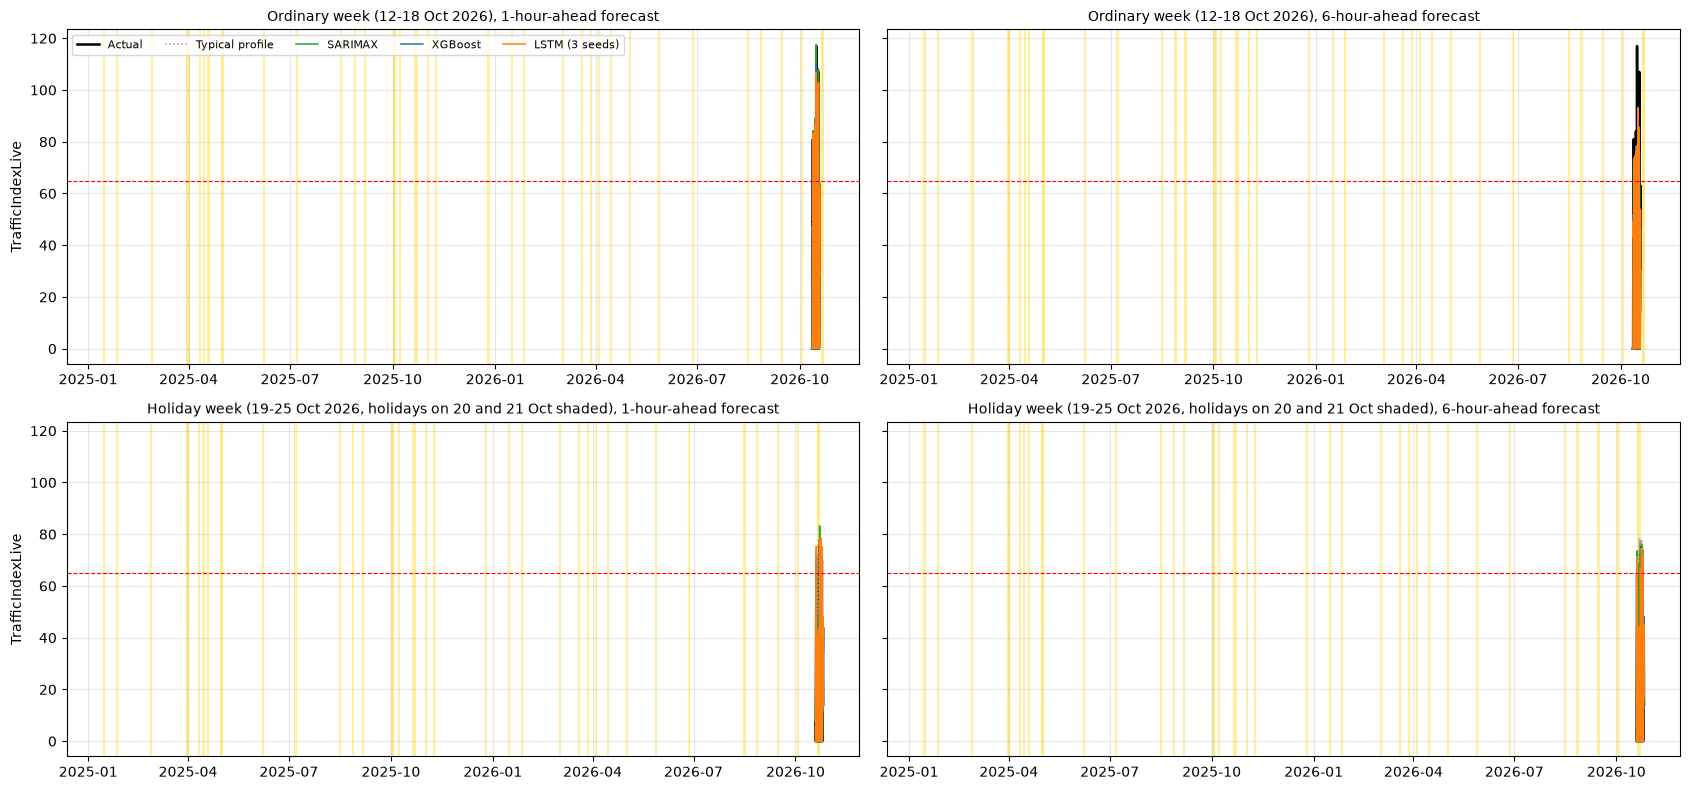

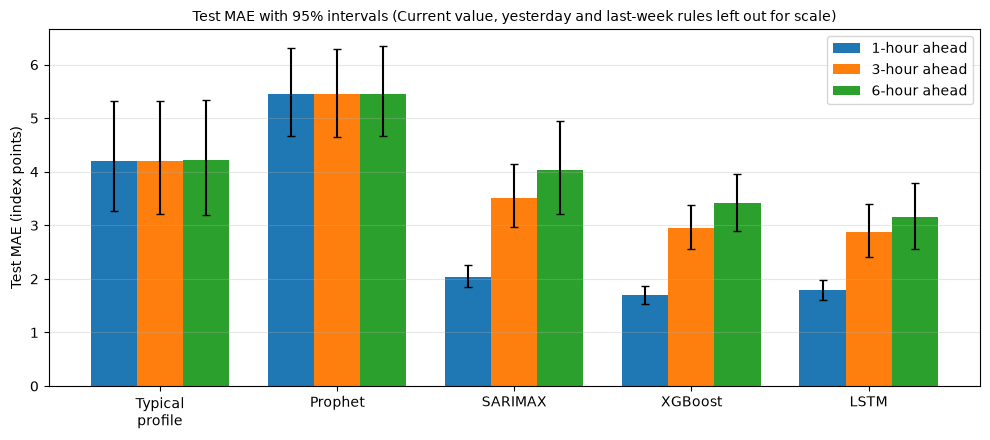

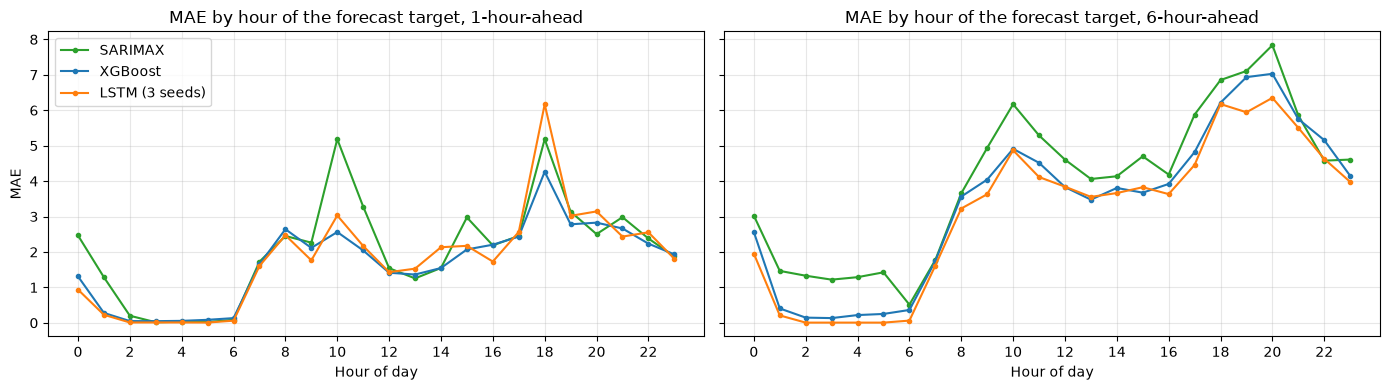

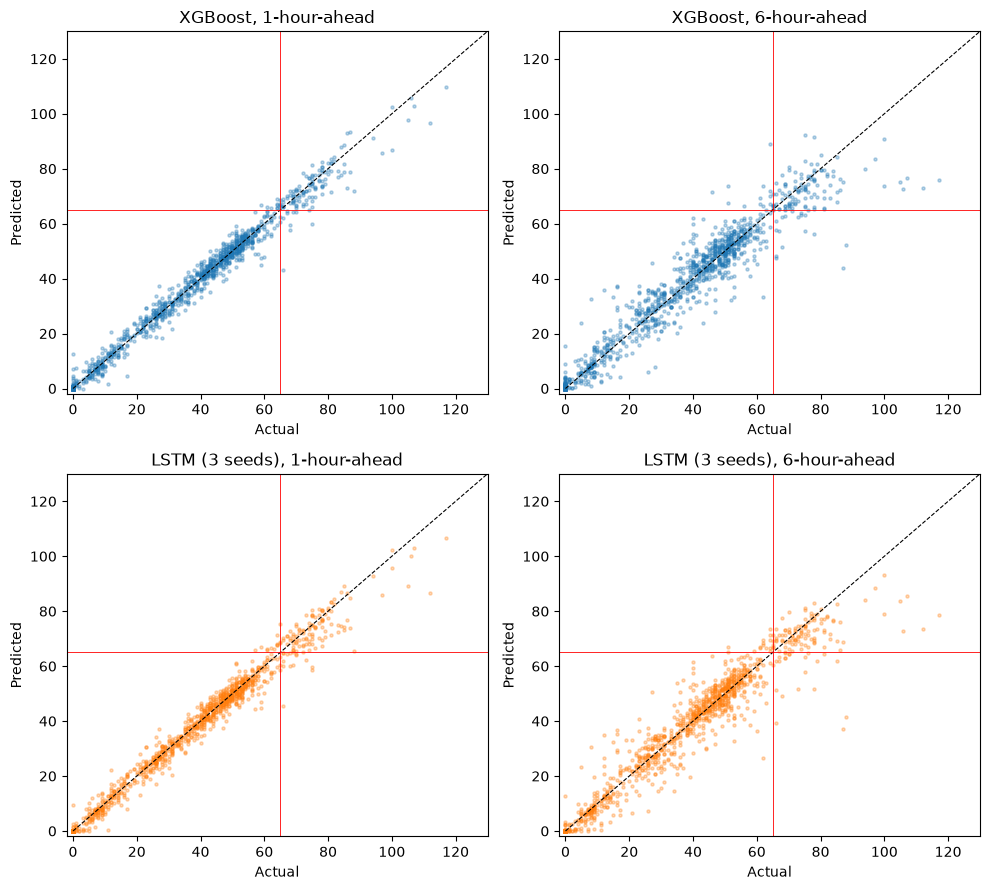

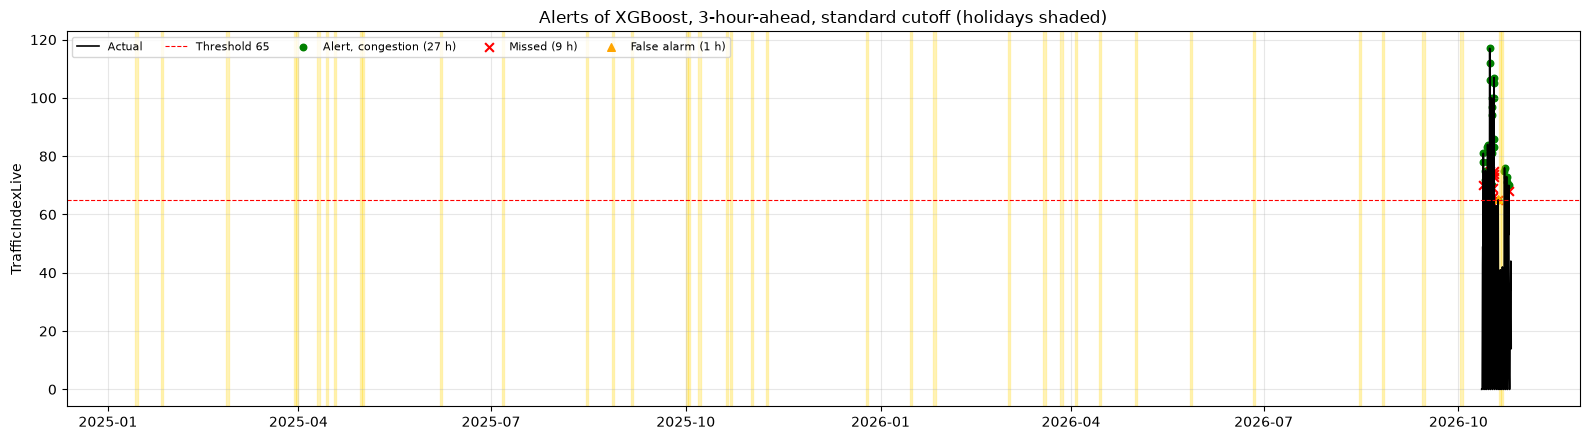

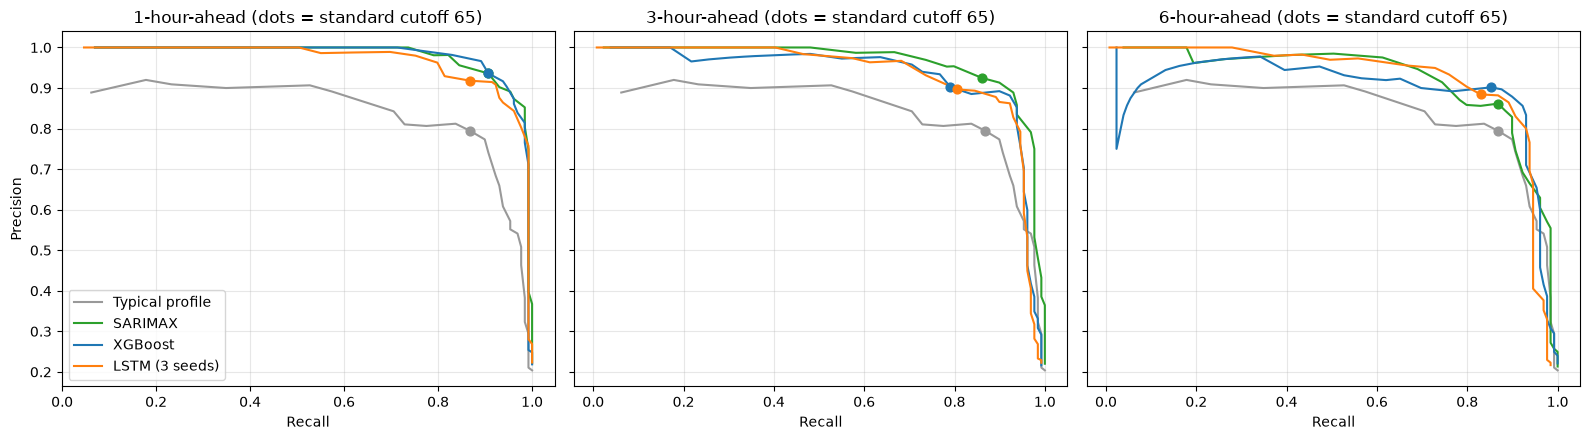

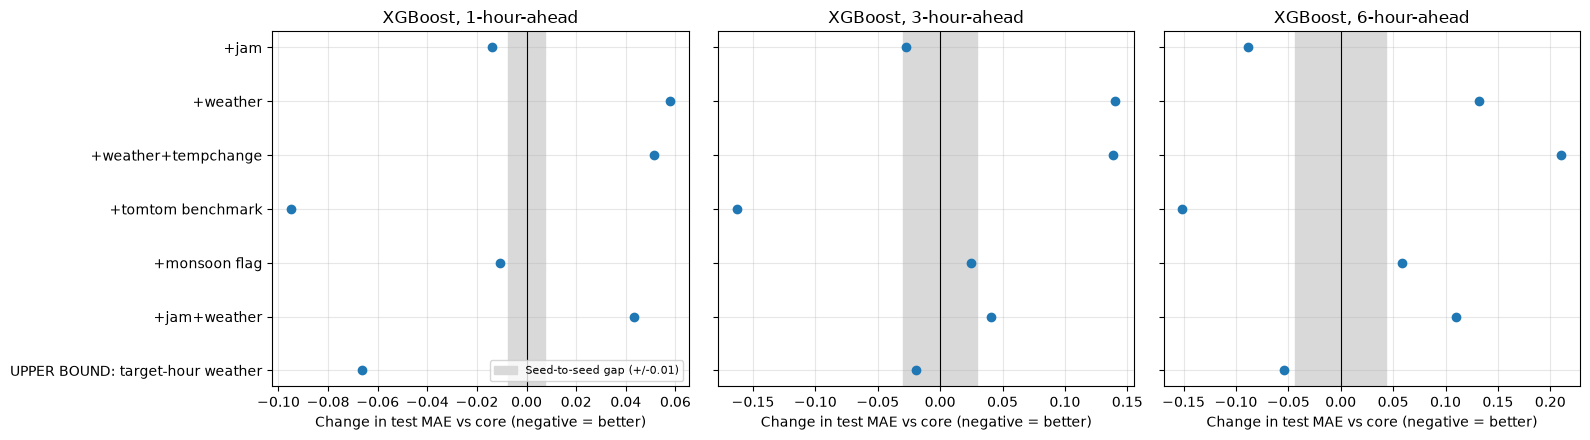

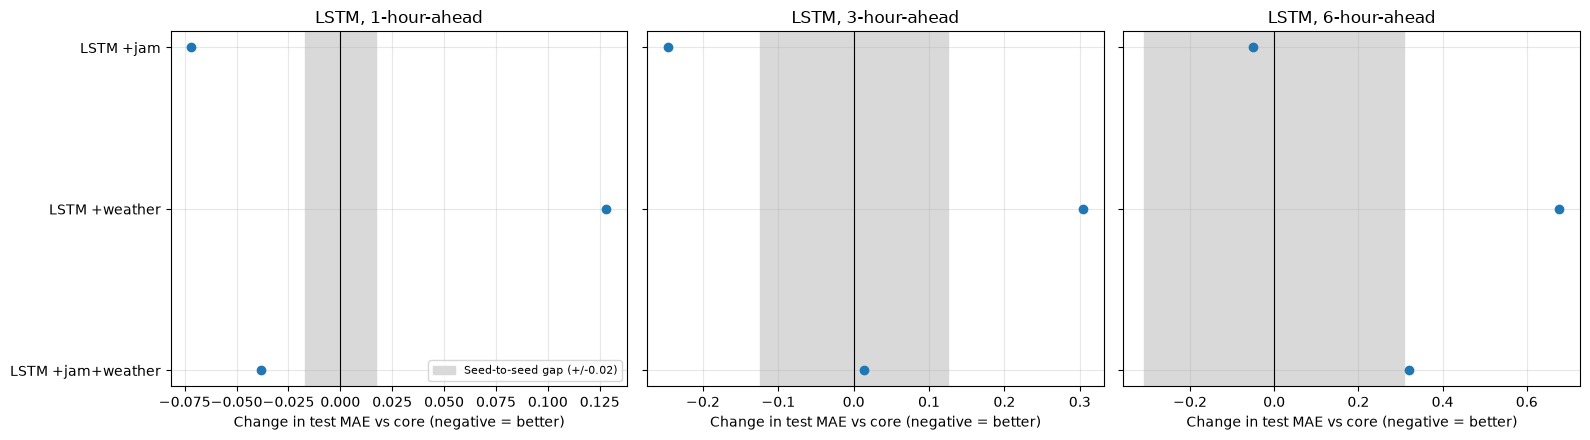

Saved: ['fig1_forecast_vs_actual.png', 'fig2_mae_with_ci.png', 'fig3_error_by_hour.png', 'fig4_actual_vs_predicted.png', 'fig5_alert_timeline.png', 'fig6_precision_recall.png', 'fig7a_ablation_xgb.png', 'fig7b_ablation_lstm.png']


In [7]:
import os, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

os.makedirs("../results/figures", exist_ok=True)
P = pd.read_csv("../results/predictions_val_test.csv", parse_dates=["origin", "target_time"])
T = P[P.split == "test"].copy()
with open("../data/processed/model_inputs/config.json") as f:
    hol_days = pd.to_datetime(json.load(f)["holidays"])

XG, LS, SX, TP = "XGBoost (core)", "LSTM (core, 3-seed avg)", "SARIMAX", "Typical profile (train)"
colors = {XG: "tab:blue", LS: "tab:orange", SX: "tab:green", TP: "0.6"}
label = {XG: "XGBoost", LS: "LSTM (3 seeds)", SX: "SARIMAX", TP: "Typical profile"}
THR = 65.0

def save(name):
    plt.tight_layout()
    plt.savefig(f"../results/figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# 1. Forecast vs actual
windows = [("Ordinary week (12-18 Oct 2026)", "2026-10-12", "2026-10-18 23:00"),
           ("Holiday week (19-25 Oct 2026, holidays on 20 and 21 Oct shaded)", "2026-10-19", "2026-10-25 23:00")]
fig, axes = plt.subplots(2, 2, figsize=(17, 8), sharey=True)
for r, (title, a, b) in enumerate(windows):
    for c, h in enumerate([1, 6]):
        ax = axes[r, c]
        g = T[(T.h == h) & (T.model == XG) & (T.target_time >= a) & (T.target_time <= b)].sort_values("target_time")
        ax.plot(g.target_time, g.actual, color="black", lw=1.8, label="Actual")
        for m in [TP, SX, XG, LS]:
            gm = T[(T.h == h) & (T.model == m) & (T.target_time >= a) & (T.target_time <= b)].sort_values("target_time")
            ax.plot(gm.target_time, gm.pred, color=colors[m], lw=1.1, label=label[m], ls=":" if m == TP else "-")
        for d in hol_days:
            ax.axvspan(d, d + pd.Timedelta(days=1), color="gold", alpha=0.25)
        ax.axhline(THR, color="red", lw=0.8, ls="--")
        ax.set_title(f"{title}, {h}-hour-ahead forecast", fontsize=10)
        ax.grid(alpha=0.3)
        if r == 0 and c == 0:
            ax.legend(fontsize=8, ncol=5, loc="upper left")
axes[0, 0].set_ylabel("TrafficIndexLive"); axes[1, 0].set_ylabel("TrafficIndexLive")
save("fig1_forecast_vs_actual")

# 2. Test MAE with 95% intervals
ci = pd.read_csv("../results/test_mae_ci.csv")
show_models = [TP, "Prophet", SX, XG, LS]
names = ["Typical\nprofile", "Prophet", "SARIMAX", "XGBoost", "LSTM"]
fig, ax = plt.subplots(figsize=(10, 4.5))
w = 0.26
for i, h in enumerate([1, 3, 6]):
    d = ci[ci.h == h].set_index("model").loc[show_models]
    ax.bar(np.arange(len(show_models)) + (i - 1) * w, d.MAE, w, label=f"{h}-hour ahead",
           yerr=[d.MAE - d.lo, d.hi - d.MAE], capsize=3)
ax.set_xticks(range(len(show_models))); ax.set_xticklabels(names)
ax.set_ylabel("Test MAE (index points)"); ax.grid(axis="y", alpha=0.3); ax.legend()
ax.set_title("Test MAE with 95% intervals (Current value, yesterday and last-week rules left out for scale)", fontsize=10)
save("fig2_mae_with_ci")

# 3. Error by hour of day
T["hour"] = T["target_time"].dt.hour
T["abs_err"] = (T["pred"] - T["actual"]).abs()
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, h in zip(axes, [1, 6]):
    for m in [SX, XG, LS]:
        s = T[(T.h == h) & (T.model == m)].groupby("hour")["abs_err"].mean()
        ax.plot(s.index, s.values, color=colors[m], label=label[m], marker="o", ms=3)
    ax.set_title(f"MAE by hour of the forecast target, {h}-hour-ahead"); ax.set_xlabel("Hour of day")
    ax.set_xticks(range(0, 24, 2)); ax.grid(alpha=0.3)
axes[0].set_ylabel("MAE"); axes[0].legend()
save("fig3_error_by_hour")

# 4. Actual vs predicted
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for r, m in enumerate([XG, LS]):
    for c, h in enumerate([1, 6]):
        g = T[(T.h == h) & (T.model == m)]
        axes[r, c].scatter(g.actual, g.pred, s=5, alpha=0.3, color=colors[m])
        axes[r, c].plot([0, 130], [0, 130], "k--", lw=0.8)
        axes[r, c].axhline(THR, color="red", lw=0.6); axes[r, c].axvline(THR, color="red", lw=0.6)
        axes[r, c].set_title(f"{label[m]}, {h}-hour-ahead"); axes[r, c].set_xlabel("Actual"); axes[r, c].set_ylabel("Predicted")
        axes[r, c].set_xlim(-2, 130); axes[r, c].set_ylim(-2, 130)
save("fig4_actual_vs_predicted")

# 5. Alert timeline (change MODEL, H and the dates below to look at other cases)
MODEL, H_, a, b = XG, 3, "2026-10-12", "2026-10-25 23:00"
g = T[(T.h == H_) & (T.model == MODEL) & (T.target_time >= a) & (T.target_time <= b)].sort_values("target_time")
act, prd = g.actual >= THR, g.pred >= THR
tp, fn, fp = act & prd, act & ~prd, ~act & prd
fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(g.target_time, g.actual, color="black", lw=1.2, label="Actual")
ax.axhline(THR, color="red", ls="--", lw=0.8, label=f"Threshold {THR:.0f}")
ax.scatter(g.target_time[tp], g.actual[tp], color="green", s=22, label=f"Alert, congestion ({tp.sum()} h)")
ax.scatter(g.target_time[fn], g.actual[fn], color="red", marker="x", s=40, label=f"Missed ({fn.sum()} h)")
ax.scatter(g.target_time[fp], g.pred[fp], color="orange", marker="^", s=30, label=f"False alarm ({fp.sum()} h)")
for d in hol_days:
    ax.axvspan(d, d + pd.Timedelta(days=1), color="gold", alpha=0.25)
ax.set_title(f"Alerts of {label[MODEL]}, {H_}-hour-ahead, standard cutoff (holidays shaded)"); ax.grid(alpha=0.3)
ax.legend(ncol=5, fontsize=8, loc="upper left"); ax.set_ylabel("TrafficIndexLive")
save("fig5_alert_timeline")

# 6. Precision-recall curves on the test set (display only; no cutoff is chosen from these)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, h in zip(axes, [1, 3, 6]):
    for m in [TP, SX, XG, LS]:
        g = T[(T.h == h) & (T.model == m)]
        act = g.actual.to_numpy() >= THR
        pr, rc = [], []
        for c in np.arange(40, 91, 1.0):
            al = g.pred.to_numpy() >= c
            if al.sum() > 0:
                pr.append((al & act).sum() / al.sum()); rc.append((al & act).sum() / act.sum())
        ax.plot(rc, pr, color=colors[m], label=label[m])
        al = g.pred.to_numpy() >= THR
        ax.scatter([(al & act).sum() / act.sum()], [(al & act).sum() / max(al.sum(), 1)], color=colors[m], s=40, zorder=3)
    ax.set_title(f"{h}-hour-ahead (dots = standard cutoff 65)"); ax.set_xlabel("Recall"); ax.grid(alpha=0.3)
axes[0].set_ylabel("Precision"); axes[0].legend()
save("fig6_precision_recall")

# 7. Ablation: change in test MAE against the seed-noise band
def ablation_panel(csv, ref, seed_row, variants, title_prefix, fname):
    if not os.path.exists(csv):
        print("Missing", csv); return
    ab = pd.read_csv(csv); ab = ab[ab.split == "test"]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
    for ax, h in zip(axes, [1, 3, 6]):
        t = ab[ab.h == h].set_index("variant")["MAE"]
        noise = abs(t[seed_row] - t[ref])
        d = (t.loc[variants] - t[ref])
        ax.axvspan(-noise, noise, color="0.85", label=f"Seed-to-seed gap (+/-{noise:.2f})")
        ax.scatter(d.values, range(len(variants)), color="tab:blue", zorder=3)
        ax.axvline(0, color="k", lw=0.8)
        ax.set_yticks(range(len(variants))); ax.set_yticklabels(variants)
        ax.set_title(f"{title_prefix}, {h}-hour-ahead"); ax.set_xlabel("Change in test MAE vs core (negative = better)")
        ax.grid(alpha=0.3); ax.invert_yaxis()
    axes[0].legend(fontsize=8, loc="lower right")
    save(fname)

ablation_panel("../results/ablation_xgb.csv", "core", "core (seed 43)",
               ["+jam", "+weather", "+weather+tempchange", "+tomtom benchmark", "+monsoon flag",
                "+jam+weather", "UPPER BOUND: target-hour weather"], "XGBoost", "fig7a_ablation_xgb")
ablation_panel("../results/ablation_lstm.csv", "LSTM core (seed 42)", "LSTM core (seed 43)",
               ["LSTM +jam", "LSTM +weather", "LSTM +jam+weather"], "LSTM", "fig7b_ablation_lstm")

print("Saved:", sorted(os.listdir("../results/figures")))

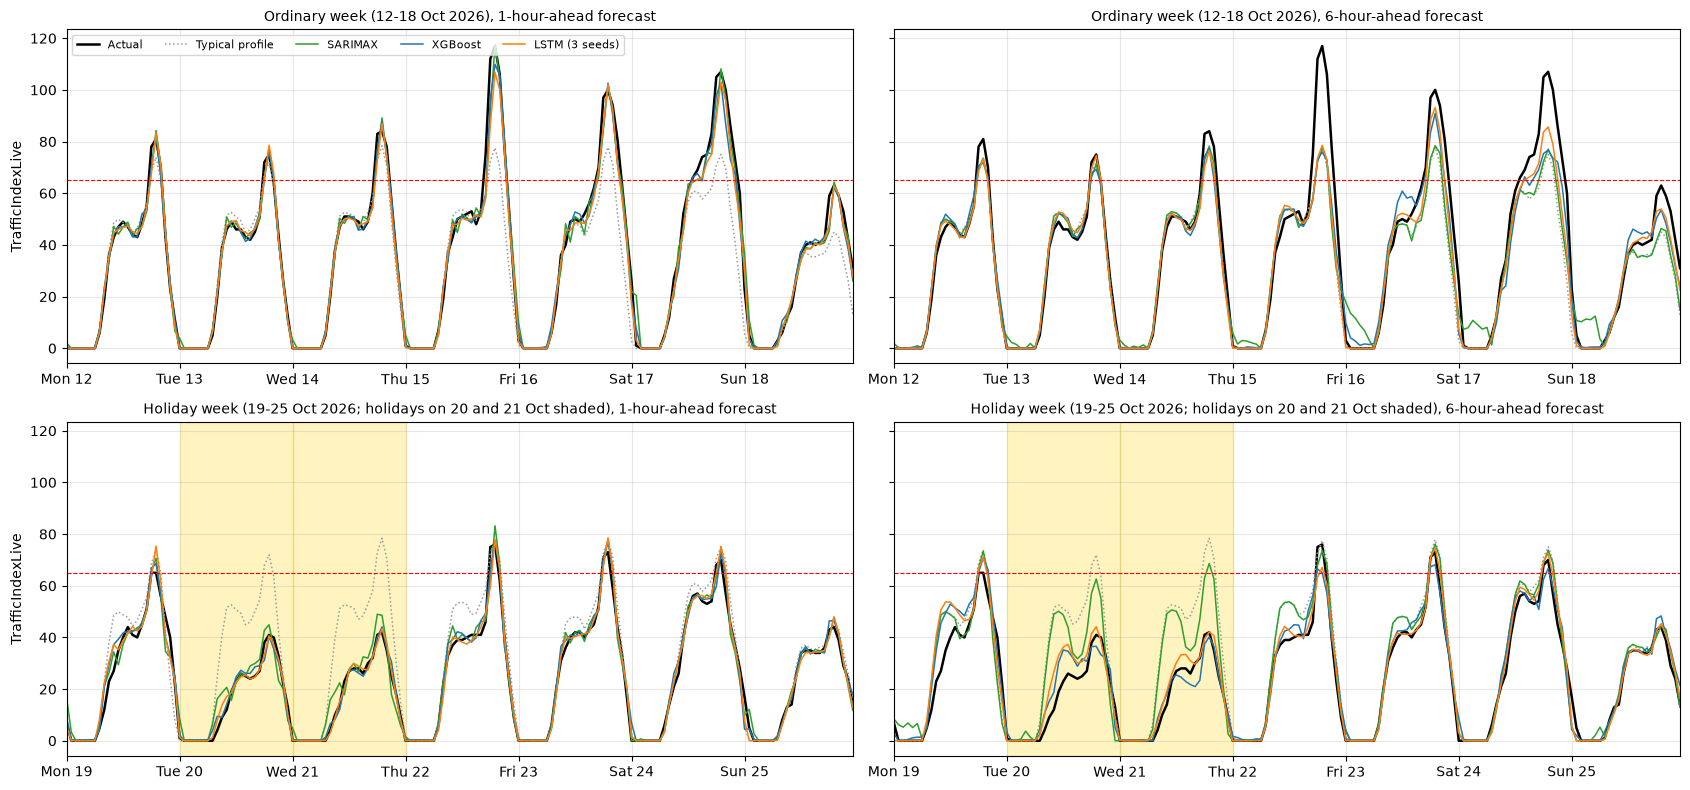

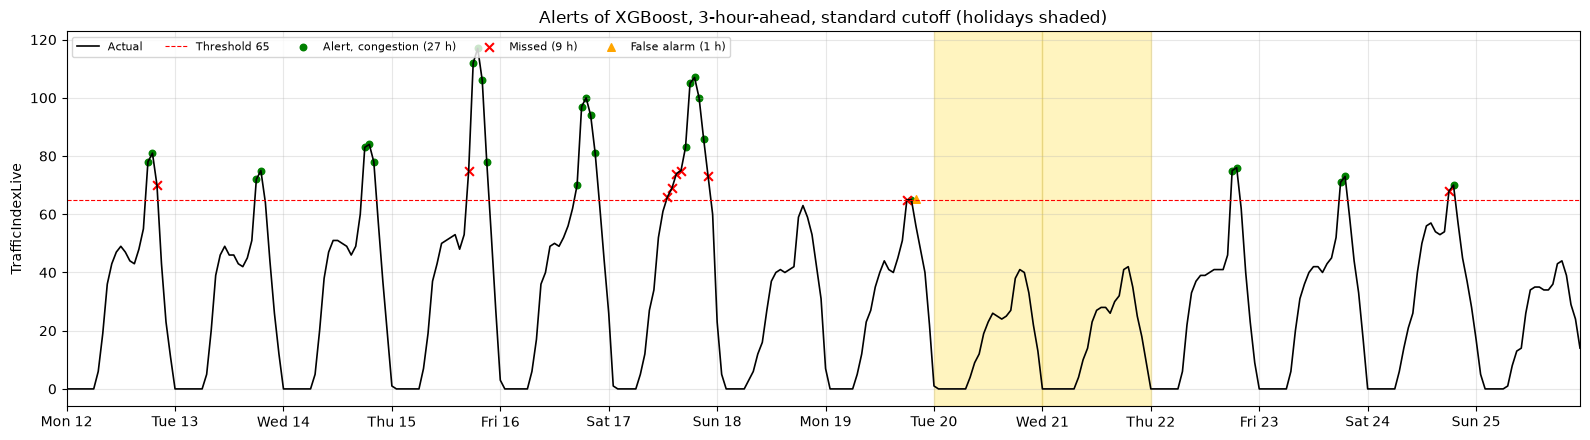

In [8]:
import os, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

os.makedirs("../results/figures", exist_ok=True)
P = pd.read_csv("../results/predictions_val_test.csv", parse_dates=["origin", "target_time"])
T = P[P.split == "test"].copy()
with open("../data/processed/model_inputs/config.json") as f:
    hol_days = pd.to_datetime(json.load(f)["holidays"])

XG, LS, SX, TP = "XGBoost (core)", "LSTM (core, 3-seed avg)", "SARIMAX", "Typical profile (train)"
colors = {XG: "tab:blue", LS: "tab:orange", SX: "tab:green", TP: "0.6"}
label = {XG: "XGBoost", LS: "LSTM (3 seeds)", SX: "SARIMAX", TP: "Typical profile"}
THR = 65.0

def shade_holidays(ax, start, end):
    for d in hol_days:
        if start <= d <= end:
            ax.axvspan(d, d + pd.Timedelta(days=1), color="gold", alpha=0.25)

def format_axis(ax, start, end):
    ax.set_xlim(start, end)
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d"))

# Figure 1: forecast vs actual
windows = [("Ordinary week (12-18 Oct 2026)", "2026-10-12", "2026-10-18 23:00"),
           ("Holiday week (19-25 Oct 2026; holidays on 20 and 21 Oct shaded)", "2026-10-19", "2026-10-25 23:00")]
fig, axes = plt.subplots(2, 2, figsize=(17, 8), sharey=True)
for r, (title, a, b) in enumerate(windows):
    start, end = pd.Timestamp(a), pd.Timestamp(b)
    for c, h in enumerate([1, 6]):
        ax = axes[r, c]
        g = T[(T.h == h) & (T.model == XG) & (T.target_time >= start) & (T.target_time <= end)].sort_values("target_time")
        ax.plot(g.target_time, g.actual, color="black", lw=1.8, label="Actual")
        for m in [TP, SX, XG, LS]:
            gm = T[(T.h == h) & (T.model == m) & (T.target_time >= start) & (T.target_time <= end)].sort_values("target_time")
            ax.plot(gm.target_time, gm.pred, color=colors[m], lw=1.1, label=label[m], ls=":" if m == TP else "-")
        shade_holidays(ax, start, end)
        ax.axhline(THR, color="red", lw=0.8, ls="--")
        format_axis(ax, start, end)
        ax.set_title(f"{title}, {h}-hour-ahead forecast", fontsize=10)
        ax.grid(alpha=0.3)
        if r == 0 and c == 0:
            ax.legend(fontsize=8, ncol=5, loc="upper left")
axes[0, 0].set_ylabel("TrafficIndexLive"); axes[1, 0].set_ylabel("TrafficIndexLive")
plt.tight_layout()
plt.savefig("../results/figures/fig1_forecast_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

# Figure 5: alert timeline (change MODEL, H_, a and b to look at other cases)
MODEL, H_, a, b = XG, 3, "2026-10-12", "2026-10-25 23:00"
start, end = pd.Timestamp(a), pd.Timestamp(b)
g = T[(T.h == H_) & (T.model == MODEL) & (T.target_time >= start) & (T.target_time <= end)].sort_values("target_time")
act, prd = g.actual >= THR, g.pred >= THR
tp, fn, fp = act & prd, act & ~prd, ~act & prd
fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(g.target_time, g.actual, color="black", lw=1.2, label="Actual")
ax.axhline(THR, color="red", ls="--", lw=0.8, label=f"Threshold {THR:.0f}")
ax.scatter(g.target_time[tp], g.actual[tp], color="green", s=22, label=f"Alert, congestion ({tp.sum()} h)")
ax.scatter(g.target_time[fn], g.actual[fn], color="red", marker="x", s=40, label=f"Missed ({fn.sum()} h)")
ax.scatter(g.target_time[fp], g.pred[fp], color="orange", marker="^", s=30, label=f"False alarm ({fp.sum()} h)")
shade_holidays(ax, start, end)
format_axis(ax, start, end)
ax.set_title(f"Alerts of {label[MODEL]}, {H_}-hour-ahead, standard cutoff (holidays shaded)")
ax.grid(alpha=0.3); ax.legend(ncol=5, fontsize=8, loc="upper left"); ax.set_ylabel("TrafficIndexLive")
plt.tight_layout()
plt.savefig("../results/figures/fig5_alert_timeline.png", dpi=150, bbox_inches="tight")
plt.show()

Holiday-free full weeks (start, highest peak): [('2026-09-07', np.float64(79.0)), ('2026-09-21', np.float64(87.0)), ('2026-10-05', np.float64(82.0)), ('2026-10-12', np.float64(117.0))]
Ordinary week chosen: starting 2026-09-21 (peak closest to the median of those weeks)


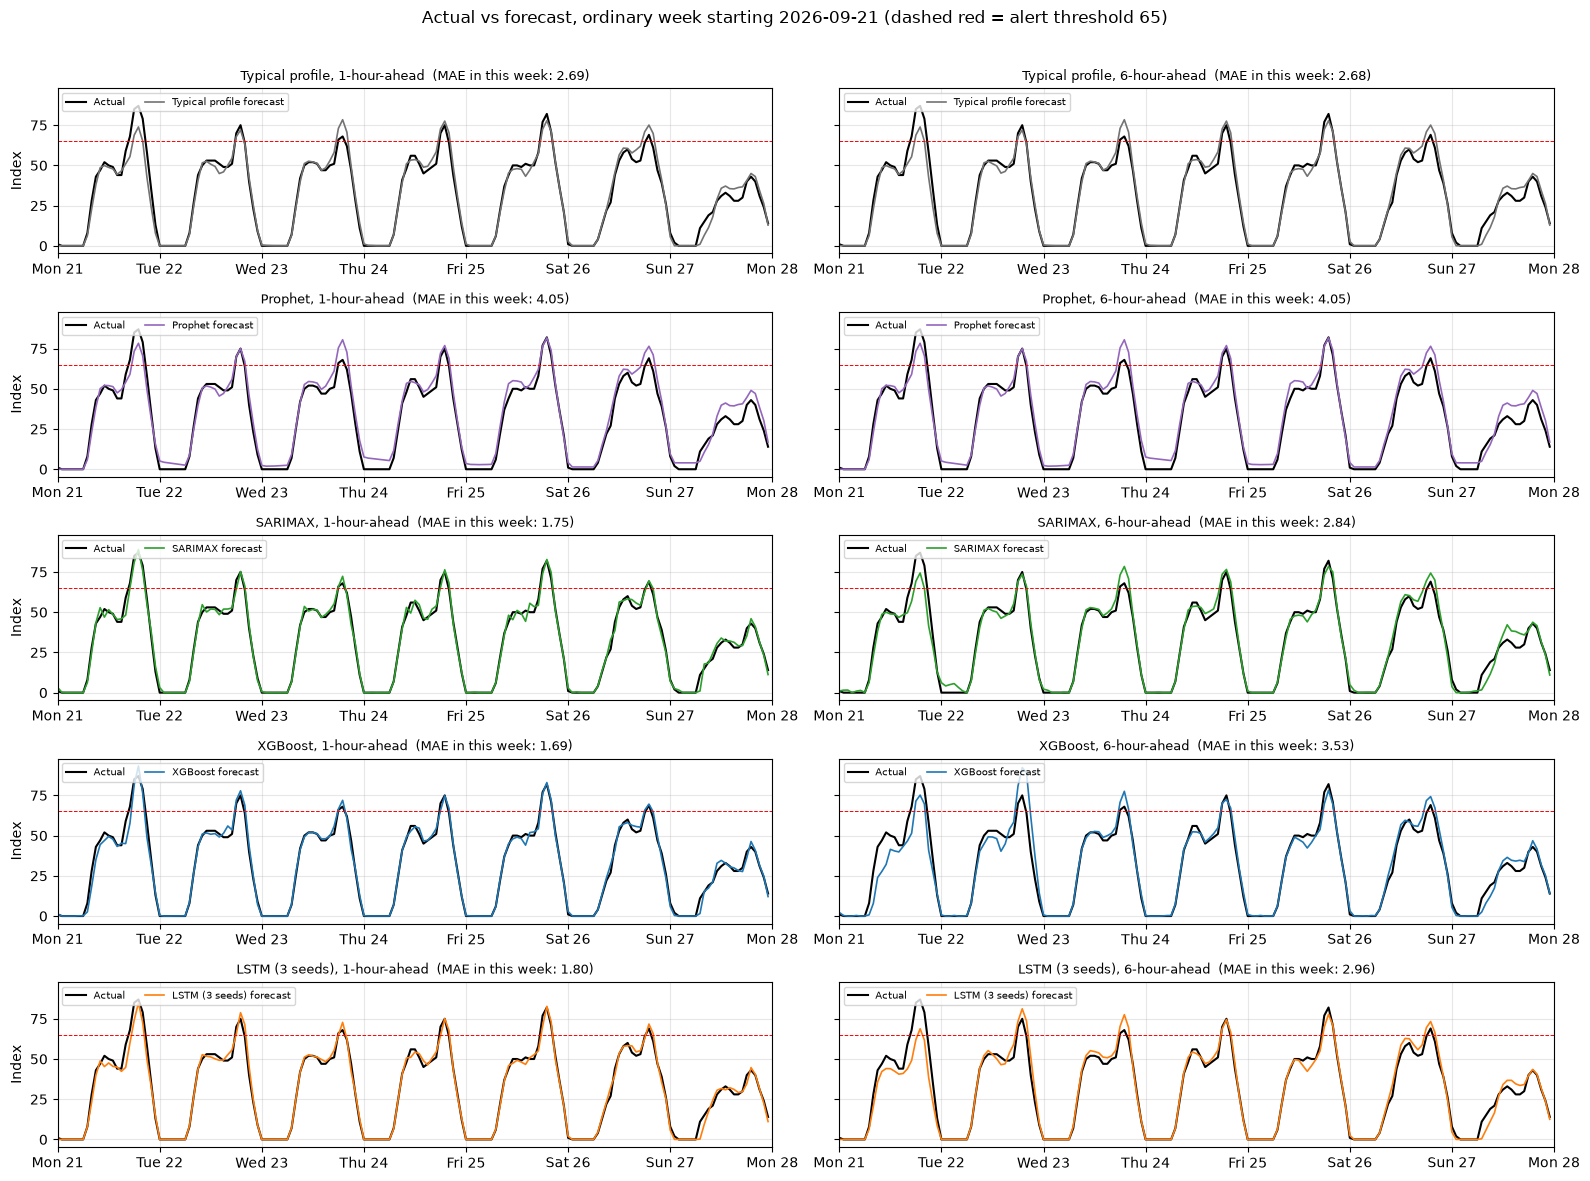

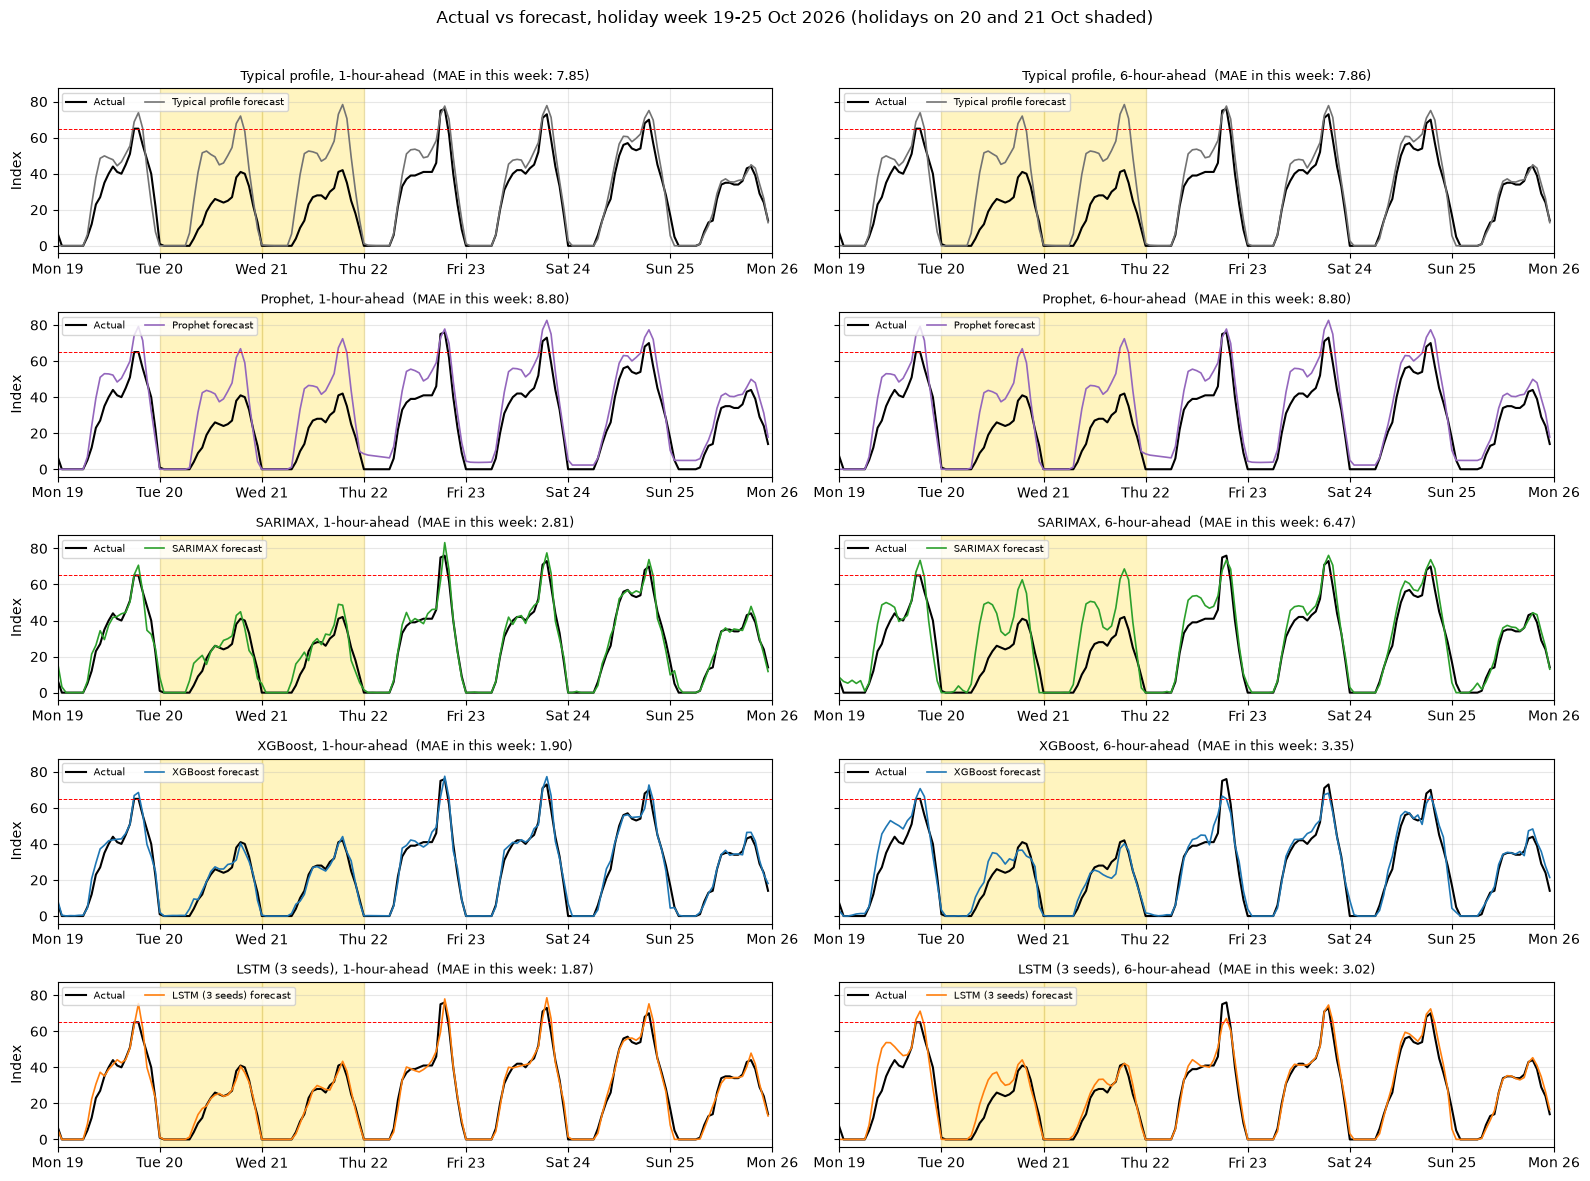

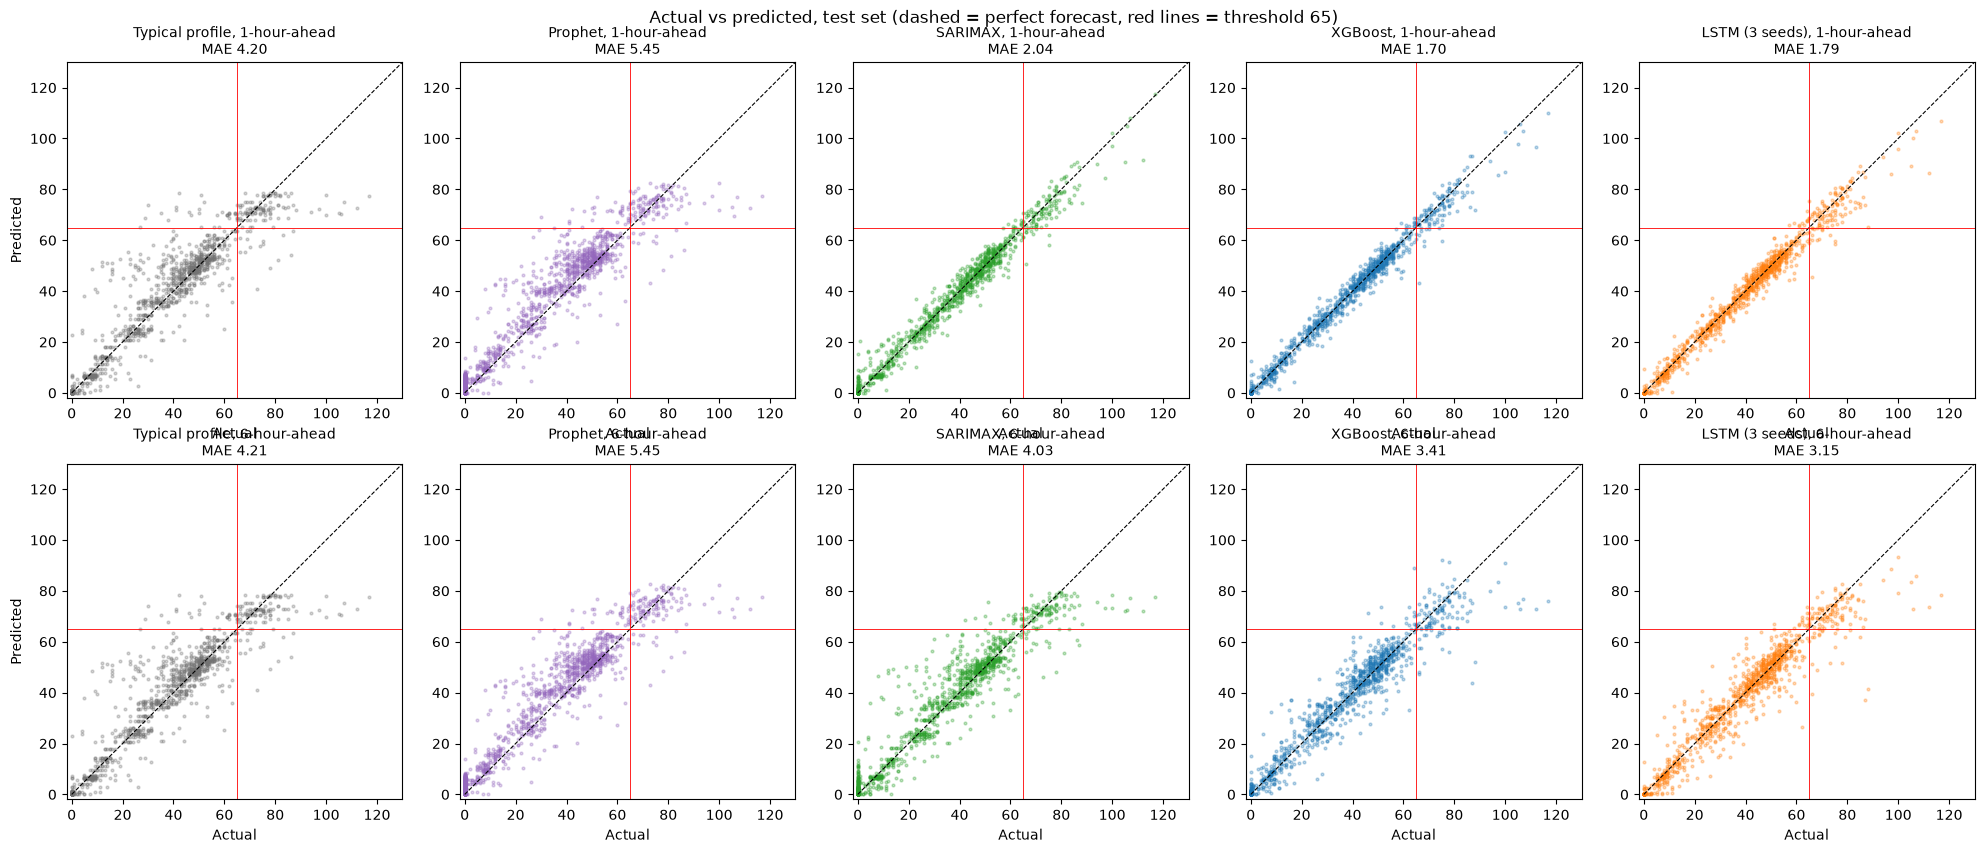

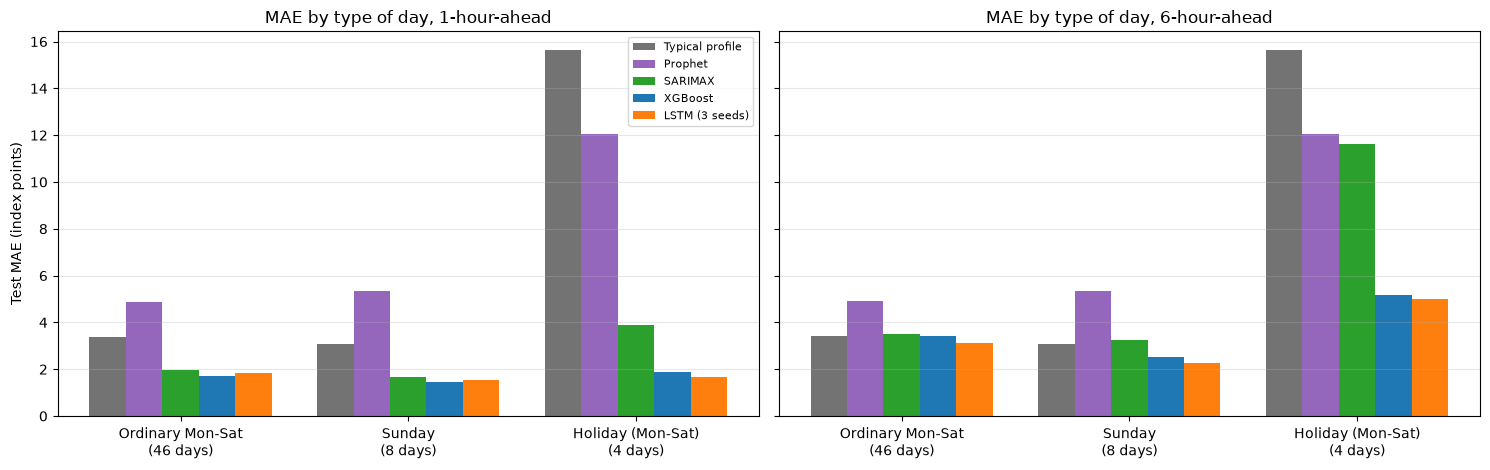

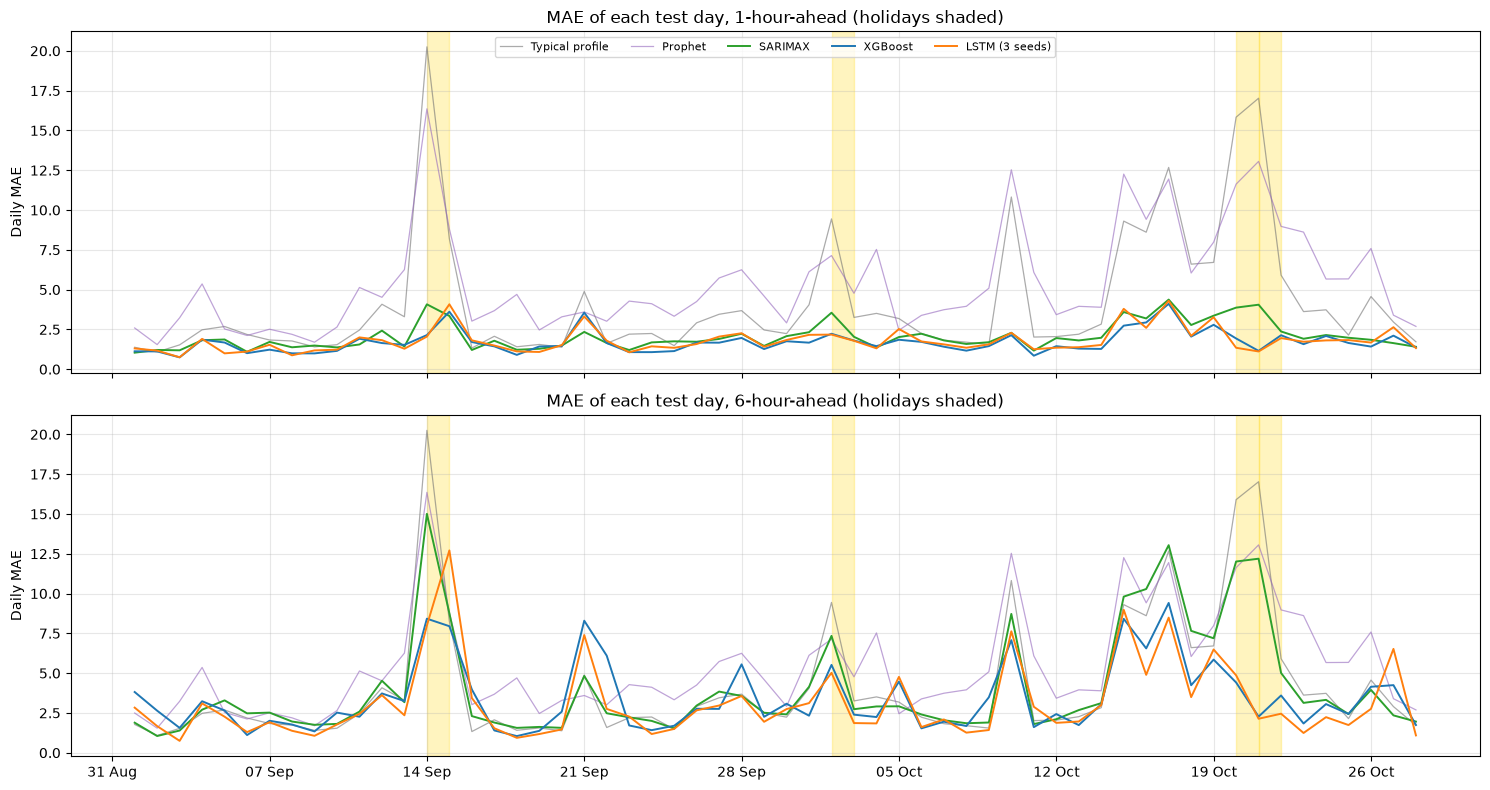

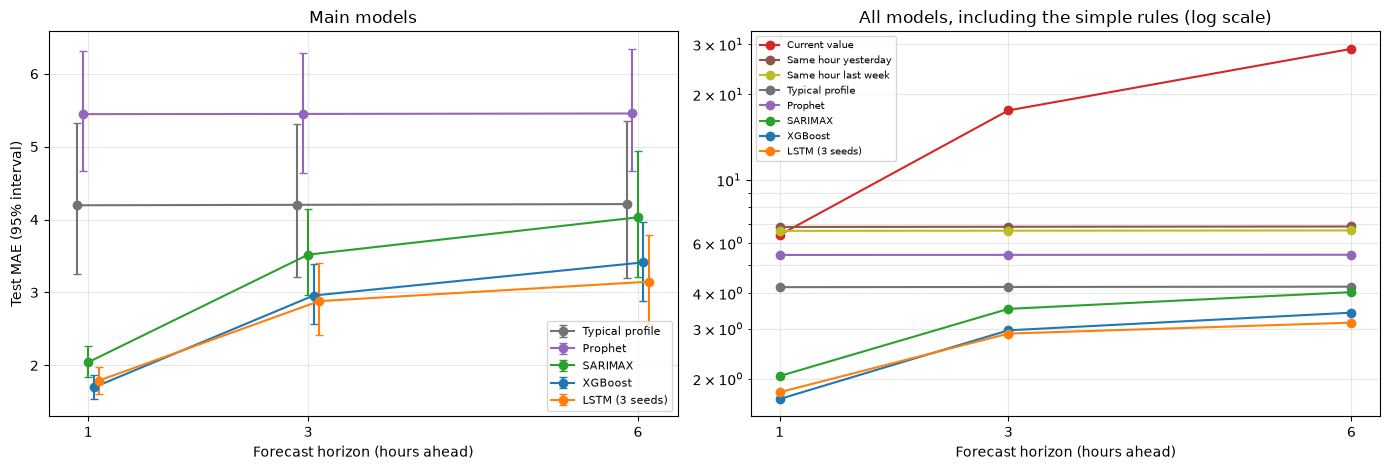

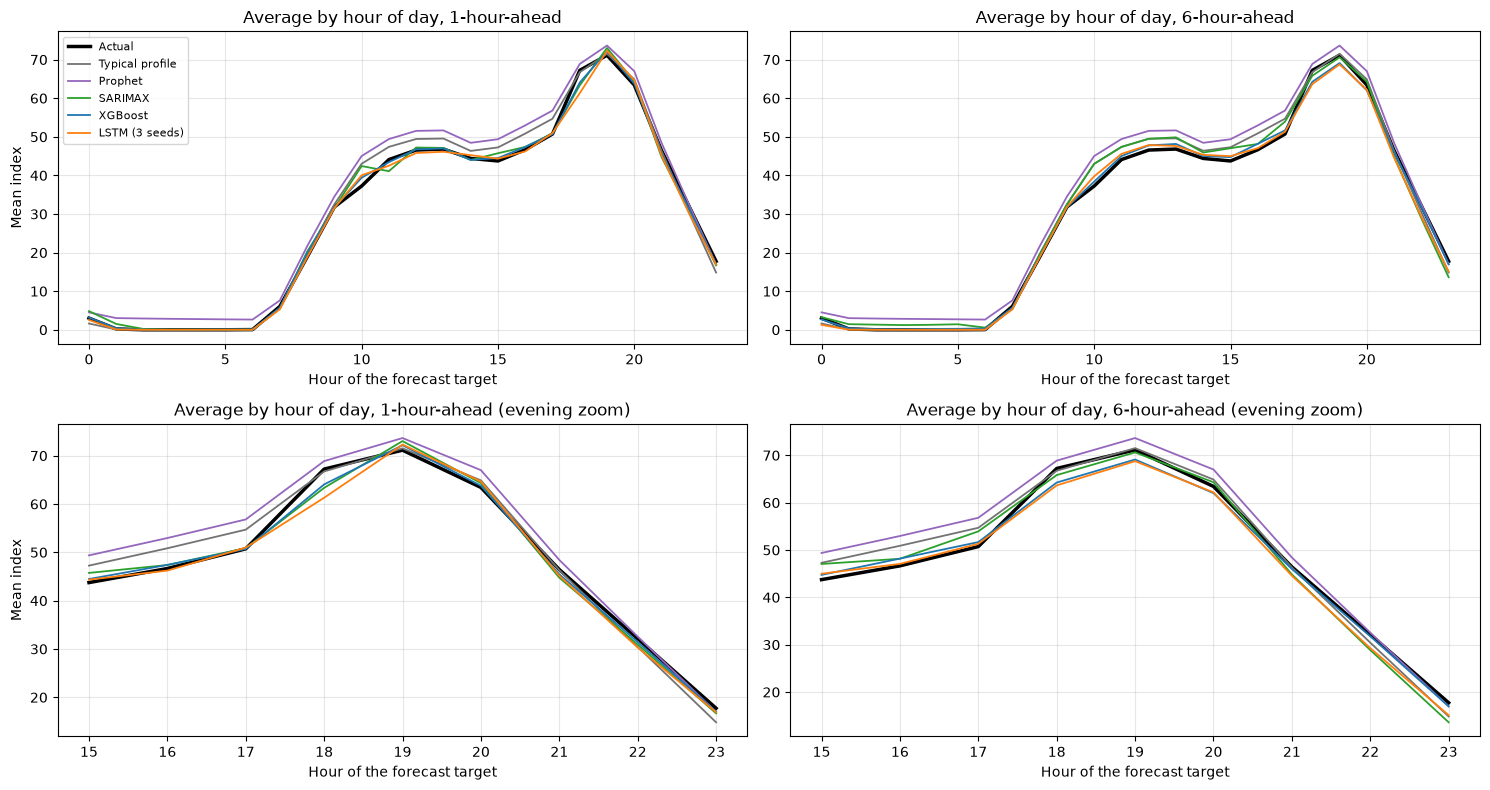


Mean bias at 6 hours in the evening hours (positive = over-predicting):
hour                      18   19   20   21
model                                      
LSTM (core, 3-seed avg) -3.6 -2.4 -1.3 -1.9
SARIMAX                 -1.4 -0.5  0.9 -1.6
XGBoost (core)          -3.0 -2.0 -1.4 -0.4

Saved: ['fig10_scatter_all_models.png', 'fig11_mae_by_day_type.png', 'fig12_daily_mae.png', 'fig13_mae_vs_horizon.png', 'fig14_average_daily_profile.png', 'fig1_forecast_vs_actual.png', 'fig8_per_model_ordinary_week.png', 'fig9_per_model_holiday_week.png']


In [9]:
import os, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

os.makedirs("../results/figures", exist_ok=True)
P = pd.read_csv("../results/predictions_val_test.csv", parse_dates=["origin", "target_time"])
T = P[P.split == "test"].copy()
T["err"] = T["pred"] - T["actual"]
T["abs_err"] = T["err"].abs()
T["day"] = T["target_time"].dt.normalize()
T["hour"] = T["target_time"].dt.hour
with open("../data/processed/model_inputs/config.json") as f:
    hol_days = pd.to_datetime(json.load(f)["holidays"])

TP, PR, SX = "Typical profile (train)", "Prophet", "SARIMAX"
XG, LS = "XGBoost (core)", "LSTM (core, 3-seed avg)"
five = [TP, PR, SX, XG, LS]
label = {TP: "Typical profile", PR: "Prophet", SX: "SARIMAX", XG: "XGBoost", LS: "LSTM (3 seeds)"}
colors = {TP: "0.45", PR: "tab:purple", SX: "tab:green", XG: "tab:blue", LS: "tab:orange"}
THR = 65.0
test_start, test_end = T["day"].min(), T["day"].max()

def save(name):
    plt.tight_layout()
    plt.savefig(f"../results/figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def shade_holidays(ax, start, end):
    for d in hol_days:
        if start <= d <= end:
            ax.axvspan(d, d + pd.Timedelta(days=1), color="gold", alpha=0.25)

# ---------- choose the ordinary week ----------
base = T[(T.h == 1) & (T.model == XG)]
test_days = set(base["day"].unique())
hol_set = set(hol_days)
cands = []
for m in sorted(d for d in test_days if d.day_of_week == 0):
    wk = list(pd.date_range(m, periods=7))
    if all(d in test_days for d in wk) and not any(d in hol_set for d in wk):
        cands.append((m, base[base["day"].isin(wk)]["actual"].max()))
if cands:
    med = np.median([c[1] for c in cands])
    calm = min(cands, key=lambda c: abs(c[1] - med))[0]
    print("Holiday-free full weeks (start, highest peak):", [(str(c[0].date()), c[1]) for c in cands])
    print("Ordinary week chosen: starting", calm.date(), "(peak closest to the median of those weeks)")
else:
    calm = pd.Timestamp("2026-10-12")
    print("No holiday-free full week found, using 12 Oct 2026")

# ---------- Figures 8 and 9: one panel per model ----------
def per_model_figure(start, title, fname):
    start = pd.Timestamp(start)
    end = start + pd.Timedelta(days=7) - pd.Timedelta(hours=1)
    fig, axes = plt.subplots(len(five), 2, figsize=(16, 2.4 * len(five)), sharey=True)
    for r, m in enumerate(five):
        for c, h in enumerate([1, 6]):
            ax = axes[r, c]
            g = T[(T.h == h) & (T.model == m) & (T.target_time >= start) & (T.target_time <= end)].sort_values("target_time")
            ax.plot(g.target_time, g.actual, color="black", lw=1.5, label="Actual")
            ax.plot(g.target_time, g.pred, color=colors[m], lw=1.2, label=f"{label[m]} forecast")
            ax.axhline(THR, color="red", lw=0.7, ls="--")
            shade_holidays(ax, start, end)
            ax.set_xlim(start, end + pd.Timedelta(hours=1))
            ax.xaxis.set_major_locator(mdates.DayLocator())
            ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d"))
            ax.set_title(f"{label[m]}, {h}-hour-ahead  (MAE in this week: {g.abs_err.mean():.2f})", fontsize=9)
            ax.grid(alpha=0.3)
            ax.legend(fontsize=7, loc="upper left", ncol=2)
        axes[r, 0].set_ylabel("Index")
    fig.suptitle(title, fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.savefig(f"../results/figures/{fname}.png", dpi=150, bbox_inches="tight")
    plt.show()

per_model_figure(calm, f"Actual vs forecast, ordinary week starting {calm.date()} (dashed red = alert threshold 65)",
                 "fig8_per_model_ordinary_week")
per_model_figure("2026-10-19", "Actual vs forecast, holiday week 19-25 Oct 2026 (holidays on 20 and 21 Oct shaded)",
                 "fig9_per_model_holiday_week")

# ---------- Figure 10: scatter, all models ----------
fig, axes = plt.subplots(2, 5, figsize=(20, 8.5))
for r, h in enumerate([1, 6]):
    for c, m in enumerate(five):
        g = T[(T.h == h) & (T.model == m)]
        ax = axes[r, c]
        ax.scatter(g.actual, g.pred, s=4, alpha=0.3, color=colors[m])
        ax.plot([0, 130], [0, 130], "k--", lw=0.8)
        ax.axhline(THR, color="red", lw=0.6); ax.axvline(THR, color="red", lw=0.6)
        ax.set_xlim(-2, 130); ax.set_ylim(-2, 130); ax.set_aspect("equal", adjustable="box")
        ax.set_title(f"{label[m]}, {h}-hour-ahead\nMAE {g.abs_err.mean():.2f}", fontsize=10)
        ax.set_xlabel("Actual")
        if c == 0: ax.set_ylabel("Predicted")
fig.suptitle("Actual vs predicted, test set (dashed = perfect forecast, red lines = threshold 65)")
save("fig10_scatter_all_models")

# ---------- Figure 11: MAE by day type ----------
T["day_type"] = np.where(T["target_time"].dt.day_of_week == 6, "Sunday",
                  np.where(T["day"].isin(hol_days), "Holiday (Mon-Sat)", "Ordinary Mon-Sat"))
types = ["Ordinary Mon-Sat", "Sunday", "Holiday (Mon-Sat)"]
ndays = T[(T.h == 1) & (T.model == XG)].groupby("day_type")["day"].nunique()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
w = 0.16
for ax, h in zip(axes, [1, 6]):
    for i, m in enumerate(five):
        v = T[(T.h == h) & (T.model == m)].groupby("day_type")["abs_err"].mean().reindex(types)
        ax.bar(np.arange(3) + (i - 2) * w, v.values, w, label=label[m], color=colors[m])
    ax.set_xticks(range(3)); ax.set_xticklabels([f"{t}\n({int(ndays[t])} days)" for t in types])
    ax.set_title(f"MAE by type of day, {h}-hour-ahead"); ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Test MAE (index points)"); axes[0].legend(fontsize=8)
save("fig11_mae_by_day_type")

# ---------- Figure 12: daily MAE over the whole test period ----------
d = T[T.model.isin(five)].groupby(["h", "model", "day"])["abs_err"].mean().reset_index()
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
for ax, h in zip(axes, [1, 6]):
    for m in five:
        s = d[(d.h == h) & (d.model == m)]
        light = m in (TP, PR)
        ax.plot(s.day, s.abs_err, color=colors[m], lw=0.9 if light else 1.4, alpha=0.6 if light else 1, label=label[m])
    shade_holidays(ax, test_start, test_end)
    ax.set_title(f"MAE of each test day, {h}-hour-ahead (holidays shaded)"); ax.set_ylabel("Daily MAE"); ax.grid(alpha=0.3)
axes[0].legend(ncol=5, fontsize=8)
axes[1].xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
save("fig12_daily_mae")

# ---------- Figure 13: MAE vs horizon ----------
final = pd.read_csv("../results/final_metrics.csv")
ci = pd.read_csv("../results/test_mae_ci.csv")
allm = ["Current value", "Same hour yesterday", "Same hour last week", TP, PR, SX, XG, LS]
colors.update({"Current value": "tab:red", "Same hour yesterday": "tab:brown", "Same hour last week": "tab:olive"})
label.update({"Current value": "Current value", "Same hour yesterday": "Same hour yesterday", "Same hour last week": "Same hour last week"})
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for m in five:
    s = ci[ci.model == m].sort_values("h")
    axes[0].errorbar(s.h + (five.index(m) - 2) * 0.05, s.MAE, yerr=[s.MAE - s.lo, s.hi - s.MAE],
                     color=colors[m], marker="o", capsize=3, label=label[m])
axes[0].set_xticks([1, 3, 6]); axes[0].set_xlabel("Forecast horizon (hours ahead)")
axes[0].set_ylabel("Test MAE (95% interval)"); axes[0].set_title("Main models"); axes[0].grid(alpha=0.3); axes[0].legend(fontsize=8)
for m in allm:
    s = final[(final.split == "test") & (final.model == m)].sort_values("h")
    axes[1].plot(s.h, s.MAE, color=colors[m], marker="o", label=label[m])
axes[1].set_yscale("log"); axes[1].set_xticks([1, 3, 6]); axes[1].set_xlabel("Forecast horizon (hours ahead)")
axes[1].set_title("All models, including the simple rules (log scale)"); axes[1].grid(alpha=0.3, which="both"); axes[1].legend(fontsize=7)
save("fig13_mae_vs_horizon")

# ---------- Figure 14: average daily profile ----------
act = T[T.model == XG].groupby(["h", "hour"])["actual"].mean()
prd = T[T.model.isin(five)].groupby(["h", "model", "hour"])["pred"].mean()
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for c, h in enumerate([1, 6]):
    for r, hmin in enumerate([0, 15]):
        ax = axes[r, c]
        a = act[h]; a = a[a.index >= hmin]
        ax.plot(a.index, a.values, color="black", lw=2.5, label="Actual")
        for m in five:
            s = prd[(h, m)]; s = s[s.index >= hmin]
            ax.plot(s.index, s.values, color=colors[m], lw=1.3, label=label[m])
        ax.set_title(f"Average by hour of day, {h}-hour-ahead" + ("" if hmin == 0 else " (evening zoom)"))
        ax.set_xlabel("Hour of the forecast target"); ax.grid(alpha=0.3)
        if r == 0 and c == 0: ax.legend(fontsize=8)
axes[0, 0].set_ylabel("Mean index"); axes[1, 0].set_ylabel("Mean index")
save("fig14_average_daily_profile")

# Bias in the evening peak, 6 hours ahead (prediction minus actual, mean over the test set)
ev = T[(T.h == 6) & T.model.isin([SX, XG, LS]) & T.hour.isin([18, 19, 20, 21])]
print("\nMean bias at 6 hours in the evening hours (positive = over-predicting):")
print(ev.pivot_table(index="model", columns="hour", values="err").round(1).to_string())
print("\nSaved:", sorted(f for f in os.listdir("../results/figures") if f.startswith(("fig8", "fig9", "fig1"))))

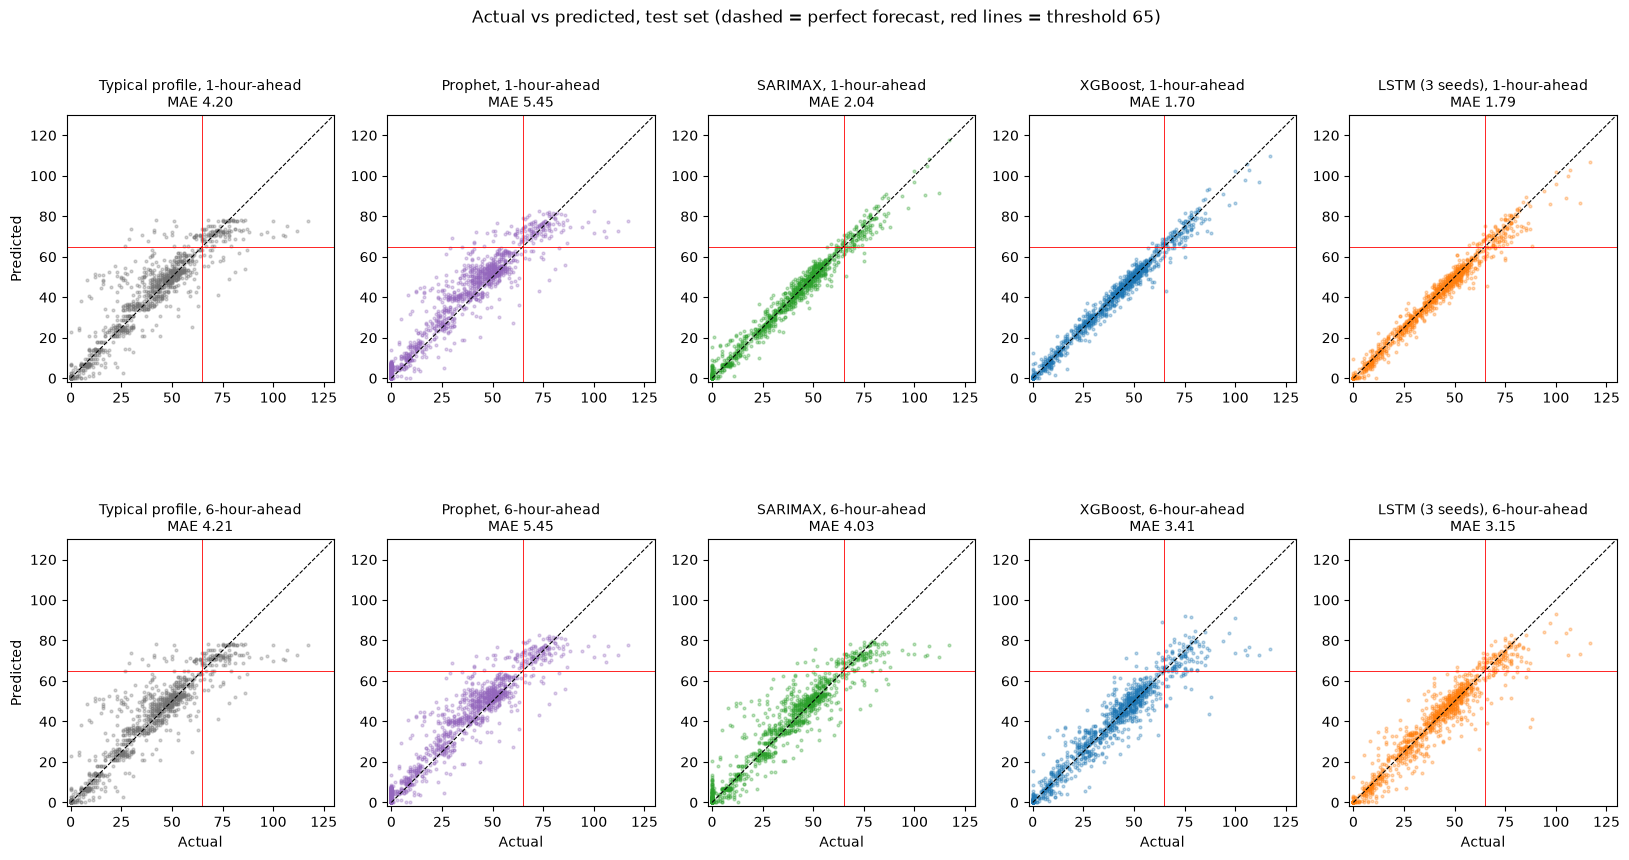

In [10]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

P = pd.read_csv("../results/predictions_val_test.csv", parse_dates=["origin", "target_time"])
T = P[P.split == "test"].copy()
T["abs_err"] = (T["pred"] - T["actual"]).abs()

five = ["Typical profile (train)", "Prophet", "SARIMAX", "XGBoost (core)", "LSTM (core, 3-seed avg)"]
label = {five[0]: "Typical profile", five[1]: "Prophet", five[2]: "SARIMAX", five[3]: "XGBoost", five[4]: "LSTM (3 seeds)"}
colors = {five[0]: "0.45", five[1]: "tab:purple", five[2]: "tab:green", five[3]: "tab:blue", five[4]: "tab:orange"}

fig, axes = plt.subplots(2, 5, figsize=(20, 9.5))
for r, h in enumerate([1, 6]):
    for c, m in enumerate(five):
        g = T[(T.h == h) & (T.model == m)]
        ax = axes[r, c]
        ax.scatter(g.actual, g.pred, s=4, alpha=0.3, color=colors[m])
        ax.plot([0, 130], [0, 130], "k--", lw=0.8)
        ax.axhline(65, color="red", lw=0.6); ax.axvline(65, color="red", lw=0.6)
        ax.set_xlim(-2, 130); ax.set_ylim(-2, 130); ax.set_aspect("equal", adjustable="box")
        ax.set_title(f"{label[m]}, {h}-hour-ahead\nMAE {g.abs_err.mean():.2f}", fontsize=10)
        if r == 1: ax.set_xlabel("Actual")
        if c == 0: ax.set_ylabel("Predicted")
fig.suptitle("Actual vs predicted, test set (dashed = perfect forecast, red lines = threshold 65)", y=0.98)
fig.subplots_adjust(hspace=0.3, top=0.9)
plt.savefig("../results/figures/fig10_scatter_all_models.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
import os, json
import numpy as np, pandas as pd

P = pd.read_csv("../results/predictions_val_test.csv", parse_dates=["origin", "target_time"])
raw = pd.read_csv("../data/processed/bangalore_traffic_weather.csv",
                  parse_dates=["LocalDateTime"]).set_index("LocalDateTime")
y_all = raw["TrafficIndexLive"].asfreq("h")
with open("../data/processed/model_inputs/config.json") as f:
    cfg = json.load(f)
hol_days = pd.to_datetime(cfg["holidays"])
T_END = pd.Timestamp(cfg["split"]["train_target_end"])

# 1. Holiday-aware typical profile: holidays count as day 6 (Sunday); training data only
def eff_dow(idx):
    return np.where(idx.normalize().isin(hol_days), 6, idx.day_of_week)

y_tr = y_all[:T_END]
prof = pd.DataFrame({"dow": eff_dow(y_tr.index), "hour": y_tr.index.hour, "y": y_tr.to_numpy()}) \
         .groupby(["dow", "hour"])["y"].mean()
print("Profile cells:", len(prof), "(expect 168) | training hours:", len(y_tr))

# 2. Predictions for every test row (same target hours as the other models)
NEW = "Holiday-aware profile"
base = P[(P.split == "test") & (P.model == "XGBoost (core)")].copy()
tt = pd.DatetimeIndex(base["target_time"])
key = pd.MultiIndex.from_arrays([eff_dow(tt), tt.hour])
base["pred"] = prof.reindex(key).to_numpy()
assert base["pred"].notna().all(), "Missing profile cells"
base["model"] = NEW
os.makedirs("../results/tables", exist_ok=True)
base.to_csv("../results/holiday_aware_profile_predictions.csv", index=False)

T = pd.concat([P[P.split == "test"], base], ignore_index=True)
T["abs_err"] = (T["pred"] - T["actual"]).abs()
T["day"] = T["target_time"].dt.normalize()
T["day_type"] = np.where(T["target_time"].dt.day_of_week == 6, "Sunday",
                  np.where(T["day"].isin(hol_days), "Holiday (Mon-Sat)", "Ordinary Mon-Sat"))

order = ["Typical profile (train)", NEW, "Prophet", "SARIMAX", "XGBoost (core)", "LSTM (core, 3-seed avg)"]
print("\nTest days by type:", T[(T.h == 1) & (T.model == NEW)].groupby("day_type")["day"].nunique().to_dict())

print("\nOverall test MAE")
print(T[T.model.isin(order)].pivot_table(index="model", columns="h", values="abs_err").loc[order].round(2).to_string())

print("\nMAE on ORDINARY Mon-Sat days only")
ordn = T[(T.day_type == "Ordinary Mon-Sat") & T.model.isin(order)]
t_ord = ordn.pivot_table(index="model", columns="h", values="abs_err").loc[order].round(2)
print(t_ord.to_string())

print("\nMAE on Sundays")
print(T[(T.day_type == "Sunday") & T.model.isin(order)].pivot_table(index="model", columns="h", values="abs_err").loc[order].round(2).to_string())
print("\nMAE on holidays (Mon-Sat)")
print(T[(T.day_type == "Holiday (Mon-Sat)") & T.model.isin(order)].pivot_table(index="model", columns="h", values="abs_err").loc[order].round(2).to_string())

# 3. Ordinary days: is each model clearly better than the holiday-aware profile?
rng = np.random.default_rng(0)
B = 2000
rows = []
for h in [1, 3, 6]:
    g = ordn[ordn.h == h]
    sums = g.groupby(["day", "model"])["abs_err"].sum().unstack()
    cnts = g.groupby(["day", "model"])["abs_err"].count().unstack()
    n = len(sums)
    idx = rng.integers(0, n, size=(B, n))
    boot = pd.DataFrame(sums.to_numpy()[idx].sum(1) / cnts.to_numpy()[idx].sum(1), columns=sums.columns)
    point = sums.sum() / cnts.sum()
    for m in ["SARIMAX", "XGBoost (core)", "LSTM (core, 3-seed avg)"]:
        dlt = boot[m] - boot[NEW]
        lo, hi = dlt.quantile([0.025, 0.975])
        rows.append({"h": h, "model": m, "diff_vs_holiday_aware_profile": point[m] - point[NEW],
                     "lo": lo, "hi": hi, "clear": bool(lo > 0 or hi < 0)})
d = pd.DataFrame(rows)
d["MAE difference (95% CI)"] = d.apply(lambda r: f"{r.diff_vs_holiday_aware_profile:+.2f} [{r.lo:+.2f}, {r.hi:+.2f}]", axis=1)
print("\nOrdinary days: model minus holiday-aware profile (negative = model is better); days resampled:", n)
print(d.pivot(index="model", columns="h", values="MAE difference (95% CI)").to_string())
print("\nClear (interval excludes 0)?")
print(d.pivot(index="model", columns="h", values="clear").to_string())

t_ord.to_csv("../results/tables/table7_ordinary_days_mae.csv")
d.to_csv("../results/tables/table8_vs_holiday_aware_profile.csv", index=False)
print("\nSaved table7 and table8 to ../results/tables/")

Profile cells: 168 (expect 168) | training hours: 12949

Test days by type: {'Holiday (Mon-Sat)': 4, 'Ordinary Mon-Sat': 46, 'Sunday': 8}

Overall test MAE
h                           1     3     6
model                                    
Typical profile (train)  4.20  4.20  4.21
Holiday-aware profile    3.65  3.65  3.66
Prophet                  5.45  5.45  5.45
SARIMAX                  2.04  3.52  4.03
XGBoost (core)           1.70  2.96  3.41
LSTM (core, 3-seed avg)  1.79  2.88  3.15

MAE on ORDINARY Mon-Sat days only
h                           1     3     6
model                                    
Typical profile (train)  3.39  3.40  3.41
Holiday-aware profile    3.48  3.49  3.50
Prophet                  4.89  4.89  4.90
SARIMAX                  1.95  3.12  3.51
XGBoost (core)           1.72  2.99  3.41
LSTM (core, 3-seed avg)  1.84  2.93  3.14

MAE on Sundays
h                           1     3     6
model                                    
Typical profile (train)  3.07  3.07  

In [12]:
import pandas as pd
d = pd.read_csv("../results/tables/table8_vs_holiday_aware_profile.csv")
d["MAE difference (95% CI)"] = d.apply(lambda r: f"{r.diff_vs_holiday_aware_profile:+.2f} [{r.lo:+.2f}, {r.hi:+.2f}]", axis=1)
print("Ordinary days: model minus holiday-aware profile (negative = model better)")
print(d.pivot(index="model", columns="h", values="MAE difference (95% CI)").to_string())
print("\nClear (interval excludes 0)?")
print(d.pivot(index="model", columns="h", values="clear").to_string())

P = pd.read_csv("../results/predictions_val_test.csv", parse_dates=["target_time"])
H = pd.read_csv("../results/holiday_aware_profile_predictions.csv", parse_dates=["target_time"])
import json, numpy as np
hol = pd.to_datetime(json.load(open("../data/processed/model_inputs/config.json"))["holidays"])
T = pd.concat([P[P.split == "test"], H], ignore_index=True)
T["abs_err"] = (T["pred"] - T["actual"]).abs()
T["day"] = T["target_time"].dt.normalize()
T["day_type"] = np.where(T["target_time"].dt.day_of_week == 6, "Sunday", np.where(T["day"].isin(hol), "Holiday", "Ordinary"))
order = ["Typical profile (train)", "Holiday-aware profile", "SARIMAX", "XGBoost (core)", "LSTM (core, 3-seed avg)"]
for t in ["Sunday", "Holiday"]:
    print(f"\nMAE on {t} days")
    print(T[(T.day_type == t) & T.model.isin(order)].pivot_table(index="model", columns="h", values="abs_err").loc[order].round(2).to_string())

Ordinary days: model minus holiday-aware profile (negative = model better)
h                                           1                     3                     6
model                                                                                    
LSTM (core, 3-seed avg)  -1.64 [-2.25, -1.09]  -0.56 [-1.02, -0.10]  -0.36 [-0.87, +0.14]
SARIMAX                  -1.53 [-2.15, -0.98]  -0.37 [-0.75, -0.04]  +0.00 [-0.21, +0.21]
XGBoost (core)           -1.76 [-2.39, -1.21]  -0.50 [-0.99, -0.04]  -0.09 [-0.55, +0.40]

Clear (interval excludes 0)?
h                           1     3      6
model                                     
LSTM (core, 3-seed avg)  True  True  False
SARIMAX                  True  True  False
XGBoost (core)           True  True  False

MAE on Sunday days
h                           1     3     6
model                                    
Typical profile (train)  3.07  3.07  3.07
Holiday-aware profile    3.42  3.42  3.42
SARIMAX                  1.65  2.91  3.23
